## EMERGENT Analysis: Notebook 1
#### Descriptives of study data and digital health measures

### 1 - Setup

Load necessary packages, define relevant paths for data and storing figures. 

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
from tqdm import tqdm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from matplotlib.patches import Patch
from sklearn.metrics import mean_squared_error, r2_score 
from scipy.stats import pearsonr
import scipy.cluster.hierarchy as hc
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from scipy.spatial import distance
from scipy.cluster import hierarchy

import sys
sys.path.append('/home/ssm-user/bklynhlth-science/common_functions/')
from analysis import (
    scatterplot, boxplot_ttest, distribution,
    calculate_labelpad_and_left, mlr_test, cohens_d, lme_test,
    train_and_test, plot_feature_importance, scatterplot_rmse,
    train_rf_model, test_rf_model, boxplot_sites_multiple,
    boxplot_anova, distribution_grid, boxplot_sites, boxplot_sites_adj, 
    tukey_anova, boxplot_visits, boxplot_visits_multiple, boxplot_sites
)
from study_data import remove_outliers

pd.set_option('display.max_rows', None)
warnings.simplefilter(action='ignore', category=FutureWarning)

warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
figure_dir = '/home/ssm-user/bklynhlth-science/michelleworthington/emergent_analysis/figures/final_figures/notebook1_descriptives/'

In [3]:
def map_visit_names(df):
    """
    Maps 'visit' to 'visit_name' based on 'studyid' using predefined mappings.

    Args:
    -------
        df (pandas.DataFrame): DataFrame with 'studyid', 'visit', and 'visit_name' columns.

    Returns:
    -------
        pandas.DataFrame: DataFrame with 'visit_name' mapped according to 'studyid' and 'visit'.
    """

    def apply_mapping(row):
        study_mappings = {
            'kar004': {
                1: 'SCR',
                2: 'BL',
                6: 'V6',
                8: 'V8',
                9: 'V9/EOT',
            },
            'kar007': {
                1: 'SCR',
                2: 'BL',
                7: 'V6',
                8: 'V7',
                9: 'V8',
                11: 'V10/EOT',
                12: 'SF'
            },
            'kar009': {
                1: 'SCR',
                2: 'BL',
                7: 'V6',
                8: 'V7',
                9: 'V8',
                11: 'V10/EOT',
                12: 'SF'
            }
        }
        study_id = row['study']
        visit = row['visit']
        return study_mappings.get(study_id, {}).get(visit)

    df['visit_name'] = df.apply(apply_mapping, axis=1)
    return df

#### 1.1 - Load data

Load speech characteristics and vocal acoustics data from all three EMERGENT studies. Combine into larger dataset. 


In [4]:
# Speech characteritics 

df1 = pd.read_csv('/home/ssm-user/bklynhlth-science/georgiosefstathiadis/emergent_analysis/24-08-01 KAR-004 dataframe, Speech Characteristics, PANSS.csv')
df1['study'] = 'kar004'
df1['site'] = df1.id.apply(lambda x: x.split('-')[0])

df2 = pd.read_csv('/home/ssm-user/bklynhlth-science/georgiosefstathiadis/emergent_analysis/24-08-01 KAR-007 dataframe, Speech Characteristics, PANSS.csv')
df2['study'] = 'kar007'
df2['site'] = df2.id.apply(lambda x: x.split('-')[1])

df3 = pd.read_csv('/home/ssm-user/bklynhlth-science/georgiosefstathiadis/emergent_analysis/24-08-01 KAR-009 dataframe, Speech Characteristics, PANSS.csv')
df3['study'] = 'kar009'
df3['site'] = df3.id.apply(lambda x: x.split('-')[1])

# Vocal acoustics 

df1_va = pd.read_csv('/home/ssm-user/bklynhlth-science/georgiosefstathiadis/emergent_analysis/24-08-01 KAR-004 dataframe, Vocal Acoustics, PANSS.csv')
df1_va['study'] = 'kar004'
df1_va['site'] = df1_va.id.apply(lambda x: x.split('-')[0])

df2_va = pd.read_csv('/home/ssm-user/bklynhlth-science/georgiosefstathiadis/emergent_analysis/24-08-05 KAR-007 dataframe, Vocal Acoustics, PANSS.csv')
df2_va['study'] = 'kar007'
df2_va['site'] = df2_va.id.apply(lambda x: x.split('-')[1])

df3_va = pd.read_csv('/home/ssm-user/bklynhlth-science/georgiosefstathiadis/emergent_analysis/24-08-01 KAR-009 dataframe, Vocal Acoustics, PANSS.csv')
df3_va['study'] = 'kar009'
df3_va['site'] = df3_va.id.apply(lambda x: x.split('-')[1])

In [5]:
ids = ['id', 'age', 'male', 'white', 'black', 'asian', 'native/hawaiin pacific islander', 'arm', 
       'visit', 'panss_p1', 'panss_p2', 'panss_p3', 'panss_p4', 'panss_p5', 'panss_p6', 'panss_p7', 
       'panss_n1', 'panss_n2', 'panss_n3', 'panss_n4', 'panss_n5', 'panss_n6', 'panss_n7', 'panss_g1', 
       'panss_g2', 'panss_g3', 'panss_g4', 'panss_g5', 'panss_g6', 'panss_g7', 'panss_g8', 'panss_g9', 
       'panss_g10', 'panss_g11', 'panss_g12', 'panss_g13', 'panss_g14', 'panss_g15', 'panss_g16', 
       'marder_positive', 'marder_negative', 'marder_disorganized', 'marder_uncontrolled', 'marder_anxiety', 
       'panss_gtot', 'panss_ptot', 'panss_ntot', 'panss']

In [6]:
# Concatenate all

df_sc = pd.concat([df1, df2, df3], ignore_index=True)
df_sc = df_sc.loc[~df_sc.visit.isin([10, 11.0001])]

df_va = pd.concat([df1_va, df2_va, df3_va], ignore_index=True)
df_va = df_va.loc[~df_va.visit.isin([10, 11.0001])]

df = pd.merge(df_sc, df_va, on = ['id', 'age', 'study', 'site', 'male', 'white', 'black', 'asian', 'native/hawaiin pacific islander', 'arm', 
       'visit', 'panss_p1', 'panss_p2', 'panss_p3', 'panss_p4', 'panss_p5', 'panss_p6', 'panss_p7', 
       'panss_n1', 'panss_n2', 'panss_n3', 'panss_n4', 'panss_n5', 'panss_n6', 'panss_n7', 'panss_g1', 
       'panss_g2', 'panss_g3', 'panss_g4', 'panss_g5', 'panss_g6', 'panss_g7', 'panss_g8', 'panss_g9', 
       'panss_g10', 'panss_g11', 'panss_g12', 'panss_g13', 'panss_g14', 'panss_g15', 'panss_g16', 
       'marder_positive', 'marder_negative', 'marder_disorganized', 'marder_uncontrolled', 'marder_anxiety', 
       'panss_gtot', 'panss_ptot', 'panss_ntot', 'panss'], 
             how = 'outer')

### 2 - Study Data

Adjust speech length variables to account for file length. 

Separate out screening dataset to examine demographic variables.

In [7]:
# adjust Speech Length In Minutes, Speech Length In Words

df['speech_length_in_minutes_adjusted'] = df['speech_length_in_minutes'] / df['file_length']
df['speech_length_in_words_adjusted'] = df['speech_length_in_words'] / df['file_length']

In [8]:
df = map_visit_names(df)

In [9]:
# save this version of the df as a csv for later import into R analysis section
df.to_csv('/home/ssm-user/bklynhlth-science/datasets/datasets_engagements/emergent/emergent_analysis_df.csv', index=False)

In [10]:
# creating a dataframe that has data from screening only

df_screening = df[df['visit'] == 1].drop_duplicates(subset='id', keep='first')

In [13]:
df_screening['id'].nunique()

960

In [11]:
# creating a dataframe that has data from baseline only

df_bl = df[df['visit'] == 2].drop_duplicates(subset='id', keep='first')

In [12]:
df_bl['id'].nunique()

696

In [17]:
df_bl['arm'].isna().sum()

23

In [18]:
df_bl['study'].value_counts()

study
kar009    260
kar007    252
kar004    184
Name: count, dtype: int64

#### 2.1 - Size

Determine sample size at each visit.

In [12]:
# Create a dictionary with the data

data_dict = {
    "Visit": [
        "Screening", 
        "Baseline", 
        "Post-randomization", 
        "Total data points", 
    ],
    "Placebo": [
        '',
        df.loc[(df.visit == 2) & (df.arm == 0) & (~df.file_length.isna())].shape[0], 
        df.loc[(~df.visit.isin([1, 2])) & (df.arm == 0) & (~df.file_length.isna())].shape[0], 
        df.loc[(df.arm == 0) & (~df.file_length.isna())].shape[0], 
    ],
    "Treatment": [
        '', 
        df.loc[(df.visit == 2) & (df.arm == 1) & (~df.file_length.isna())].shape[0], 
        df.loc[(~df.visit.isin([1, 2])) & (df.arm == 1) & (~df.file_length.isna())].shape[0], 
        df.loc[(df.arm == 1) & (~df.file_length.isna())].shape[0], 
    ],
    "All": [
        df.loc[(df.visit == 1) & (~df.file_length.isna())].shape[0], 
        df.loc[(df.visit == 2) & (~df.file_length.isna())].shape[0], 
        df.loc[(~df.visit.isin([1, 2])) & (~df.file_length.isna())].shape[0], 
        df.loc[(~df.file_length.isna())].shape[0], 
    ]
}

# Create a DataFrame

pd.DataFrame(data_dict)

,Visit,Placebo,Treatment,All
0,Screening,,,853
1,Baseline,293,296,615
2,Post-randomization,1023,992,2015
3,Total data points,1616,1586,3483


In [13]:
# Data available for each visit 

df['visit'].value_counts()

1.0000     960
2.0000     696
8.0000     554
9.0000     526
11.0000    434
7.0000     423
12.0000    180
6.0000     170
2.0001       2
1.0001       2
Name: visit, dtype: int64

In [14]:
# Number assigned to each treatment group

contingency_table = pd.crosstab(df['visit'], df['arm'])
print(contingency_table)

arm    0.0  1.0  2.0  3.0
visit                    
1.0    337  331   45    3
2.0    337  331    2    3
6.0     86   84    0    0
7.0    220  203    0    0
8.0    287  267    0    0
9.0    272  254    0    0
11.0   220  214    0    0
12.0    89   91    0    0


#### 2.2 - Age

In [15]:
# print the min, max, mean, and median age across the dataset

print(f"min age: {df_screening['age'].min()}")
print(f"max age: {df_screening['age'].max()}")
print(f"mean age: {df_screening['age'].mean()}")
print(f"median age: {df_screening['age'].median()}")

min age: 18.0
max age: 65.0
mean age: 44.16770833333333
median age: 45.0


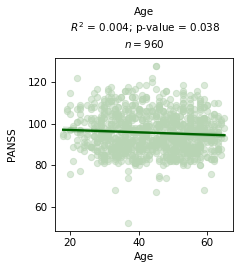

In [16]:
# Plot a scatterplot between age and PANSS with a Pearson correlation

scatterplot(df_screening, 'age', ['panss'], 'Age', 'PANSS', 'Age', 1, 'corr', dpi=75)
scatterplot(df_screening, 'age', ['panss'], 'Age', 'PANSS', 'Age', 1, 'corr', dpi=200, filename=figure_dir+'2.2_scatterplot_age_panss.png')

#### 2.3 - Sex

In [17]:
# Print the n for male and female participants

print(f"male: {df_screening[df_screening['male'] == 1]['id'].nunique()}")
print(f"female: {df_screening[df_screening['male'] == 0]['id'].nunique()}")

male: 719
female: 241


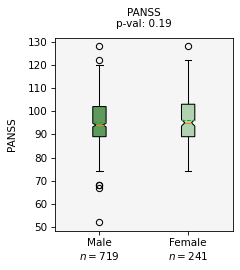

In [18]:
# Box plot for difference in PANSS by sex with a t-test for comparison

male = df_screening[df_screening['male'] == 1]['panss'].dropna()
female = df_screening[df_screening['male'] == 0]['panss'].dropna()
boxplot_ttest('PANSS', male, female, 'Male', 'Female', 1, dpi=75)
boxplot_ttest('PANSS', male, female, 'Male', 'Female', 1, dpi=200, filename=figure_dir+'2.3_boxplot_sex_panss.png')

#### 2.4 - Race

In [19]:
# Print the n for every race designation in the dataset

print(f"white: {df_screening[df_screening['white'] == 1]['id'].nunique()}")
print(f"black: {df_screening[df_screening['black'] == 1]['id'].nunique()}")
print(f"asian: {df_screening[df_screening['asian'] == 1]['id'].nunique()}")

print(f"other: {df_screening.loc[(df_screening['black'] == 0) & (df_screening['white'] == 0) & (df_screening['asian'] == 0)]['id'].nunique()}")

white: 276
black: 664
asian: 11
other: 9


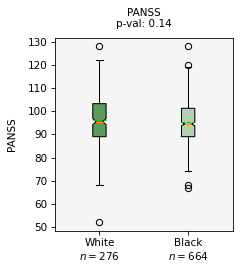

In [20]:
white = df_screening[df_screening['white'] == 1]['panss'].dropna()
black = df_screening[df_screening['black'] == 1]['panss'].dropna()
asian = df_screening[df_screening['asian'] == 1]['panss'].dropna()
other = df_screening.loc[(df_screening['black'] == 0) & (df_screening['white'] == 0) & (df_screening['asian'] == 0)]['panss'].dropna()    

# Box plot for difference in PANSS by race, with ANOVA
# boxplot_anova('PANSS', [white, black, asian, hawaiian, other], ['White', 'Black', 'Asian', 'Hawaiian', 'Other'], 1, dpi=75)
## not included here due to low n for categories 'asian' and 'other'

# Box plot for difference in PANSS by race (white and black only), with t-test

boxplot_ttest('PANSS', white, black, 'White', 'Black', 1, dpi=75)
boxplot_ttest('PANSS', white, black, 'White', 'Black', 1, dpi=200, filename=figure_dir+'2.4_boxplot_race_panss.png')

#### 2.5 - PANSS scores

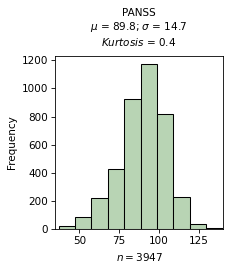

In [21]:
# Plot the PANSS distribution across the dataset using a histogram

distribution(df, 'panss', 'PANSS', 'histogram', dpi=75, x_limits=(35, 140))
distribution(df, 'panss', 'PANSS', 'histogram', dpi=200, x_limits=(35, 140), filename=figure_dir+'2.5_histogram_panss.png')

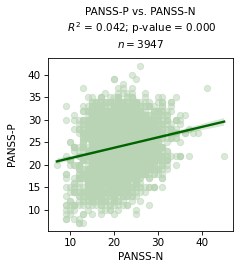

In [22]:
# Plot a scatterplot between PANSS-P and PANSS-N across the whole dataset

scatterplot(df, 'panss_ntot', ['panss_ptot'], 'PANSS-N', 'PANSS-P', 'PANSS-P vs. PANSS-N', 1, 'corr', dpi=75)
scatterplot(df, 'panss_ntot', ['panss_ptot'], 'PANSS-N', 'PANSS-P', 'PANSS-P vs. PANSS-N', 1, 'corr', dpi=200, filename=figure_dir+f"2.5_scatterplot_panns_positive_panss_negative.png")

### 3 - Digital health measures (DHMs)

#### 3.1 - List of measures

In [23]:
dhms = ['file_length', 'speech_length_in_minutes_adjusted',
       'speech_length_in_words_adjusted',
       'mean_turn_length_in_minutes', 'mean_turn_length_in_words',
       'speaker_percentage',
       'words_per_minute', 'syllables_per_minute',
       'word_pause_length_mean', 'word_pause_variability',
       'mean_pre_turn_pause', 'positive_sentiment', 'negative_sentiment',
       'lexical_richness',
       'first_person_percentage',
       'first_person_sentiment_positive', 'first_person_sentiment_negative',
       'first_person_sentiment_overall', 'word_repeat_percentage',
       'phrase_repeat_percentage',
       'word_coherence_mean', 'word_coherence_var', 'word_coherence_5_mean',
       'word_coherence_5_var', 'word_coherence_10_mean',
       'word_coherence_10_var', 'word_coherence_variability_2_mean',
       'word_coherence_variability_2_var', 'word_coherence_variability_3_mean',
       'word_coherence_variability_3_var', 'word_coherence_variability_4_mean',
       'word_coherence_variability_4_var', 'word_coherence_variability_5_mean',
       'word_coherence_variability_5_var', 'word_coherence_variability_6_mean',
       'word_coherence_variability_6_var', 'word_coherence_variability_7_mean',
       'word_coherence_variability_7_var', 'word_coherence_variability_8_mean',
       'word_coherence_variability_8_var', 'word_coherence_variability_9_mean',
       'word_coherence_variability_9_var',
       'word_coherence_variability_10_mean',
       'word_coherence_variability_10_var',
       'first_order_sentence_tangeniality_mean',
       'first_order_sentence_tangeniality_var',
       'second_order_sentence_tangeniality_mean',
       'second_order_sentence_tangeniality_var',
       'turn_to_turn_tangeniality_mean', 'turn_to_turn_tangeniality_var',
       'turn_to_turn_tangeniality_slope', 'semantic_perplexity_mean',
       'semantic_perplexity_var', 'f0_mean', 'f0_stddev', 'f1_mean', 'f1_stddev', 
       'f2_mean', 'f2_stddev', 'f3_mean', 'f3_stddev', 'f4_mean', 'f4_stddev',
       'loudness_mean', 'loudness_stddev', 'hnr_mean',
       'hnr_stddev', 'jitter', 'jitter_abs',
       'jitter_rap', 'jitter_ppq5', 'jitter_ddp', 'shimmer', 'shimmer_db',
       'shimmer_apq3', 'shimmer_apq5', 'shimmer_apq11', 'shimmer_dda',
       'gne_ratio', 'silence_ratio']

for item in dhms:
    print(item.replace('_', ' ').title())

File Length
Speech Length In Minutes Adjusted
Speech Length In Words Adjusted
Mean Turn Length In Minutes
Mean Turn Length In Words
Speaker Percentage
Words Per Minute
Syllables Per Minute
Word Pause Length Mean
Word Pause Variability
Mean Pre Turn Pause
Positive Sentiment
Negative Sentiment
Lexical Richness
First Person Percentage
First Person Sentiment Positive
First Person Sentiment Negative
First Person Sentiment Overall
Word Repeat Percentage
Phrase Repeat Percentage
Word Coherence Mean
Word Coherence Var
Word Coherence 5 Mean
Word Coherence 5 Var
Word Coherence 10 Mean
Word Coherence 10 Var
Word Coherence Variability 2 Mean
Word Coherence Variability 2 Var
Word Coherence Variability 3 Mean
Word Coherence Variability 3 Var
Word Coherence Variability 4 Mean
Word Coherence Variability 4 Var
Word Coherence Variability 5 Mean
Word Coherence Variability 5 Var
Word Coherence Variability 6 Mean
Word Coherence Variability 6 Var
Word Coherence Variability 7 Mean
Word Coherence Variability 

In [24]:
df_clean = remove_outliers(df.copy(), dhms)
df_screening_clean = remove_outliers(df_screening.copy(), dhms)
df_bl_clean = remove_outliers(df_bl.copy(), dhms)

##### 3.1.1 - Heatmap of relationships between DHMs

Below is a heatmap demonstrating the relationships between select DHMs. 

In [25]:
# limit analysis to select DHMs, excluding some of the higher order coherence measures 

new_dhms = ['file_length', 'speech_length_in_minutes_adjusted',
       'speech_length_in_words_adjusted',
       'mean_turn_length_in_minutes', 'mean_turn_length_in_words',
       'speaker_percentage', 'silence_ratio',
       'words_per_minute', 'syllables_per_minute',
       'word_pause_length_mean',
       'mean_pre_turn_pause', 
       'lexical_richness', 'word_repeat_percentage',
       'phrase_repeat_percentage',
       'first_person_percentage', 'positive_sentiment', 'negative_sentiment',
       'first_person_sentiment_positive', 'first_person_sentiment_negative',
       'first_person_sentiment_overall', 
       'word_coherence_mean', 'word_coherence_5_mean',
       'word_coherence_10_mean',
       'first_order_sentence_tangeniality_mean',
       'turn_to_turn_tangeniality_mean', 'semantic_perplexity_mean']

In [26]:
# create df with columns only for dhms

subset_df = df_clean[new_dhms].copy()

custom_labels = ['File Length', 'Speech Length, mins',
       'Speech Length, words',
       'Turn Length, mins', 'Turn Length, words',
       'Speaker Percentage', 'Silence Ratio',
       'Words/Min', 'Syllables/Min',
       'Word Pause Length',
       'Pre-turn Pause', 
       'MATTR', 'Word Repeat',
       'Phrase Repeat',
       'First Person Words', 'Pos Sentiment', 'Neg Sentiment',
       'First Person Positive', 'First Person Negative',
       'First Person Overall', 
       'Coherence', 'Coherence - 5 word',
       'Coherence - 10 word',
       'Sent. Tangentiality',
       'Response Similarity', 'Semantic Perplexity']
subset_df = subset_df.rename(columns=dict(zip(subset_df.columns, custom_labels)))

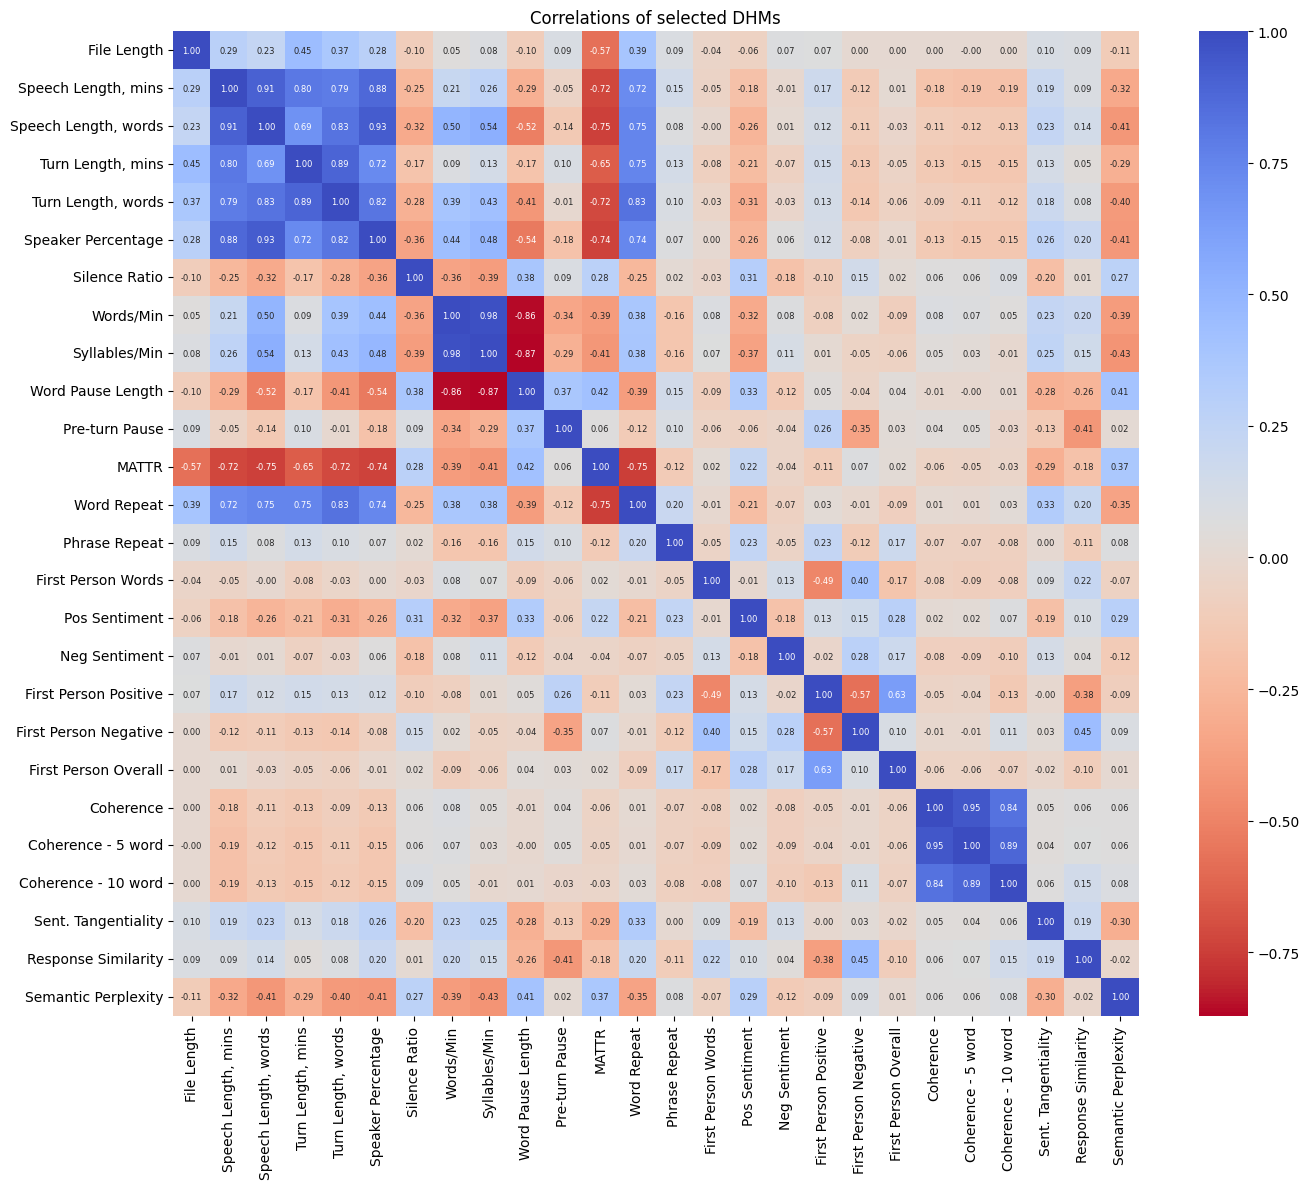

In [16]:
# create correlation matrix

correlation_matrix = subset_df.corr() 

plt.figure(figsize = (14, 12))  # Adjust figure size as needed
sns.heatmap(correlation_matrix, annot = True, cmap = "coolwarm_r", fmt = ".2f",
           annot_kws = {"size": 6})
plt.title('Correlations of selected DHMs')
plt.tight_layout() 

plt.savefig(figure_dir+f"3.1.1_correlation_heatmap.png")

plt.show()

<Figure size 1400x1200 with 0 Axes>

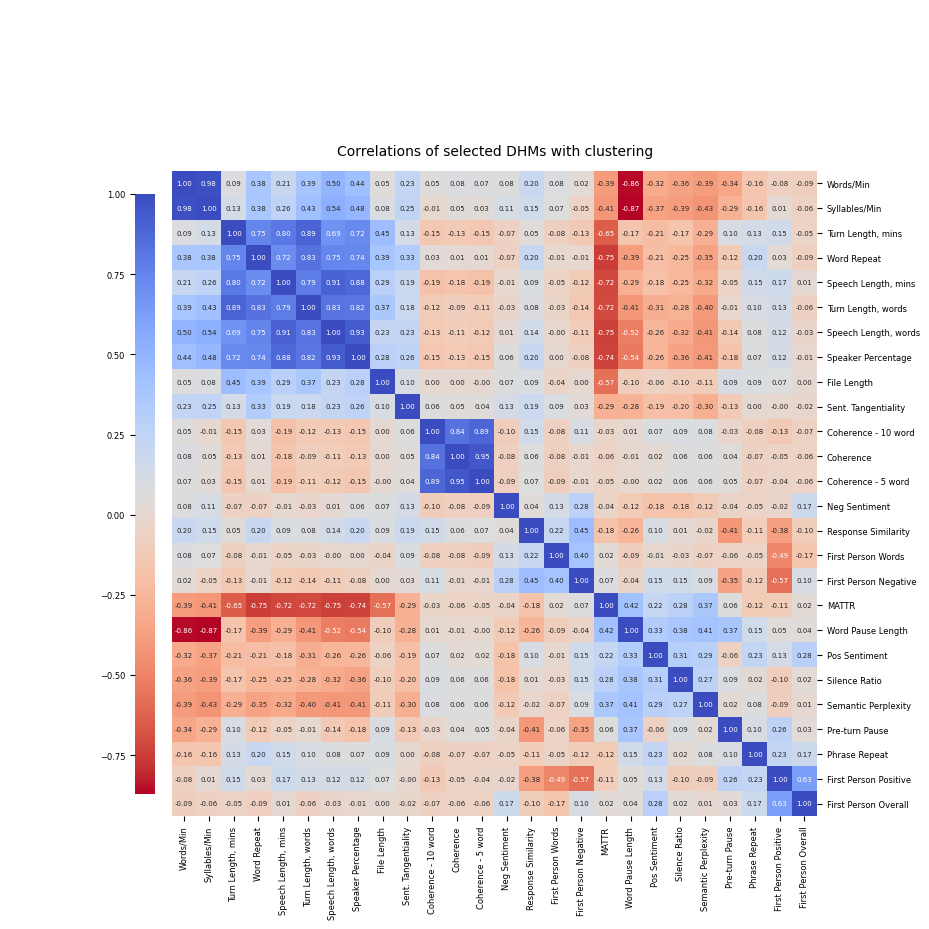

In [22]:
# correlation matrix reordered with clustering technique

correlations = subset_df.corr()
correlations_array = np.asarray(subset_df.corr())

row_linkage = hierarchy.linkage(
    distance.pdist(correlations_array), method='average')

col_linkage = hierarchy.linkage(
    distance.pdist(correlations_array.T), method='average')

plt.figure(figsize = (14, 12))
map = sns.clustermap(correlations, row_linkage=row_linkage, col_linkage=col_linkage, method="average",
               cbar_pos = (0.14,0.2,0.02,0.6), cmap="coolwarm_r", annot = True, fmt = ".2f", annot_kws = {"size": 5},
                    tree_kws={"linewidths": 0})
plt.suptitle('Correlations of selected DHMs with clustering', y = 0.85, x = 0.5, fontsize = 10)
map.ax_heatmap.tick_params(axis="both", which="major", labelsize=6)
map.cax.yaxis.set_ticks_position("left") 
map.cax.yaxis.set_label_position("left")  
#plt.setp(map.ax_heatmap.xaxis.get_majorticklabels(), rotation=45)
map.cax.tick_params(labelsize=6)

plt.savefig(figure_dir+f"3.1.2_correlation_heatmap_clustered.png", bbox_inches='tight')


plt.show()

#### 3.2 - Distributions of measures across groups

In [24]:
for dhm in dhms:
    distribution(df_clean, dhm, dhm.replace('_', ' ').title(), 'density plot', dpi=200, filename=figure_dir+f"3.2_density_{dhm}.png")

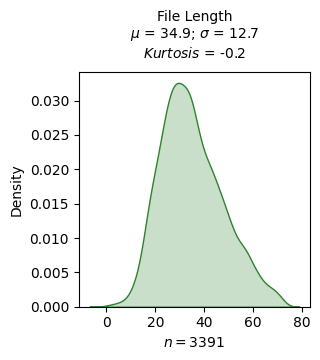

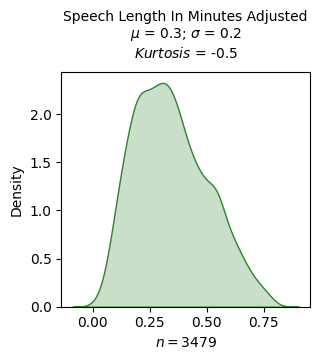

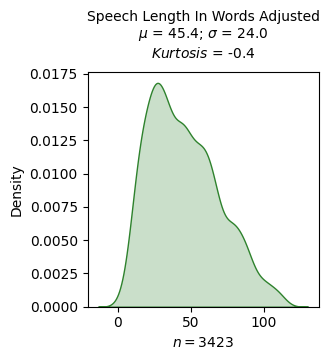

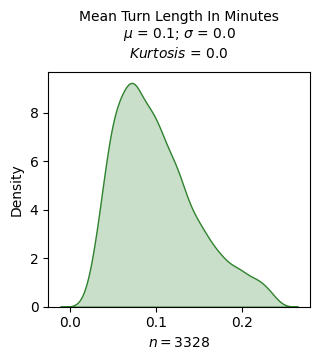

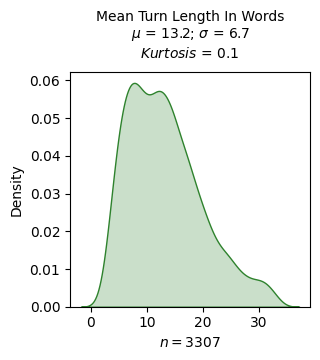

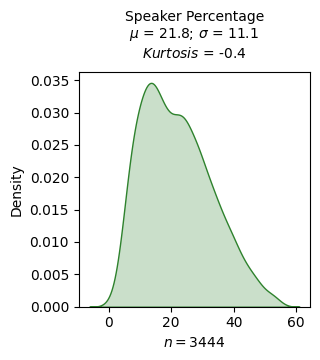

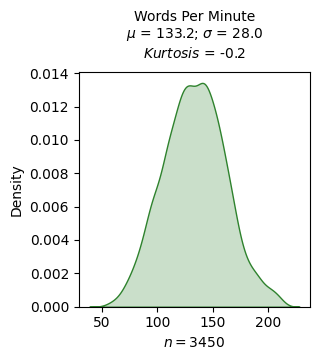

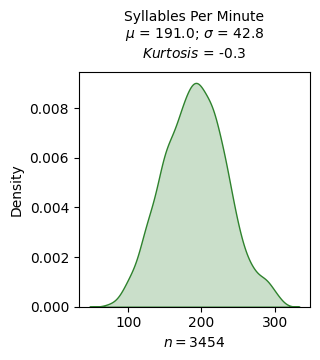

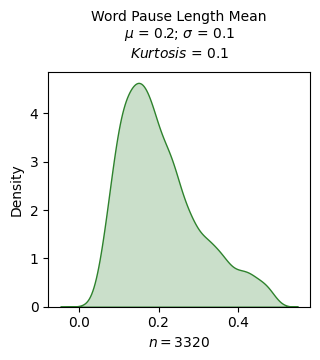

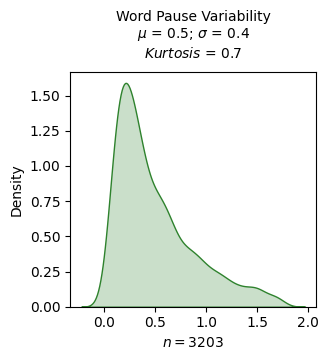

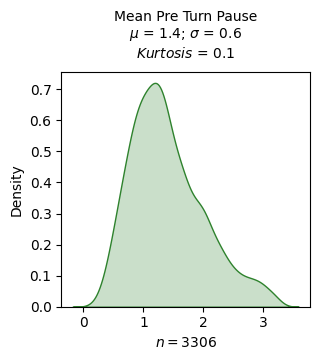

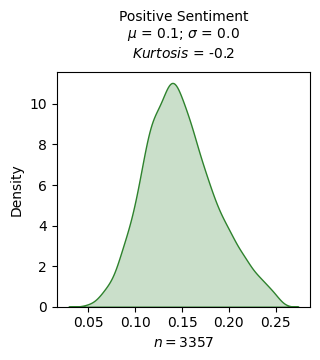

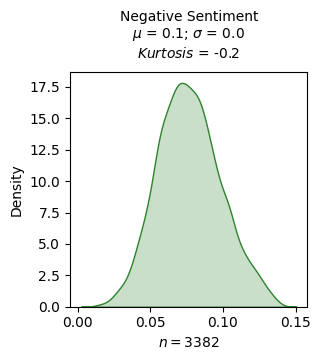

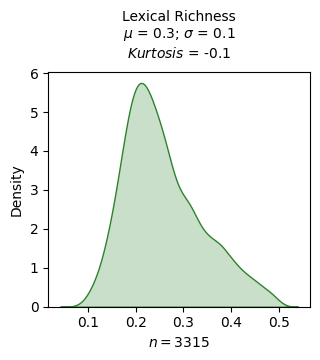

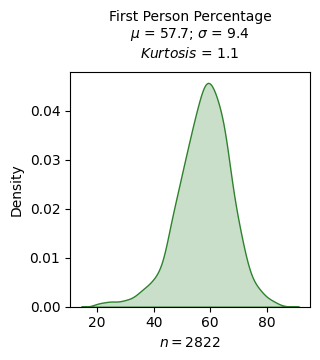

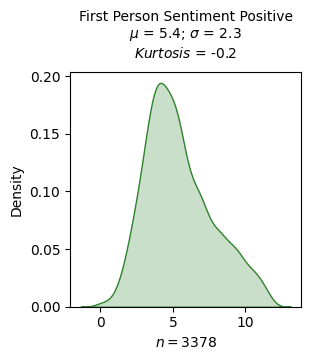

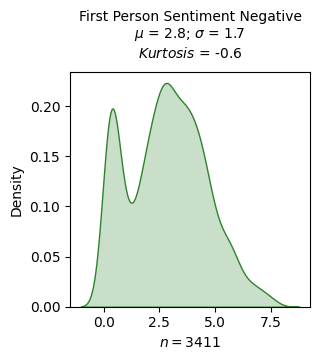

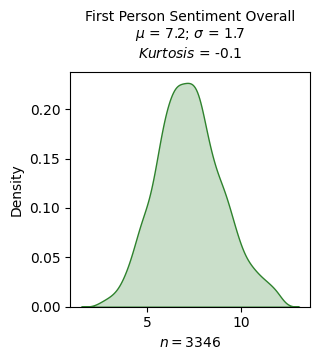

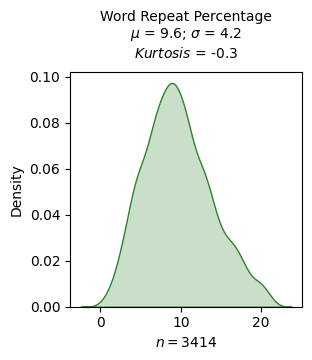

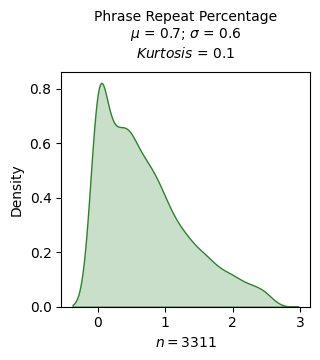

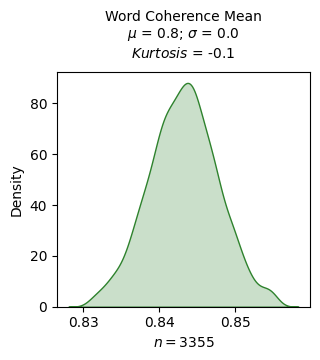

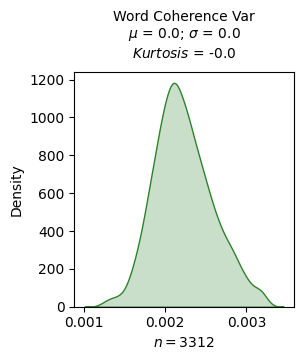

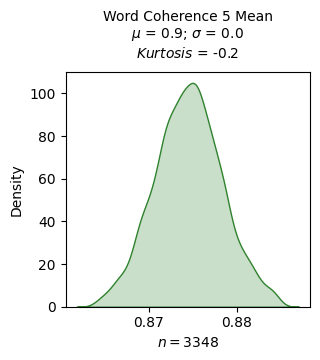

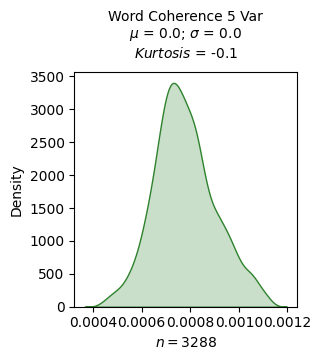

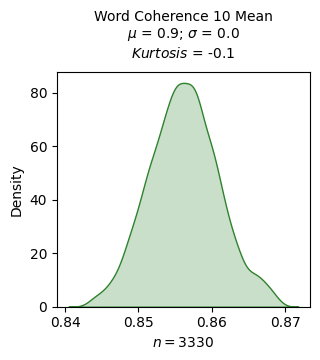

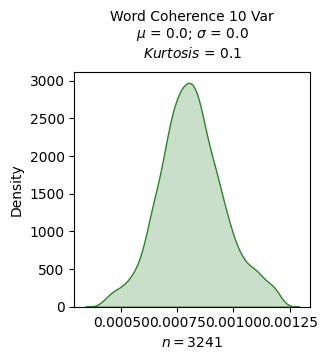

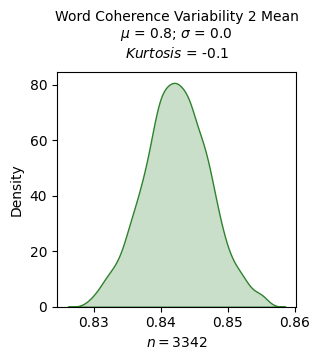

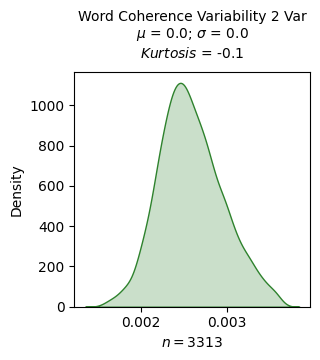

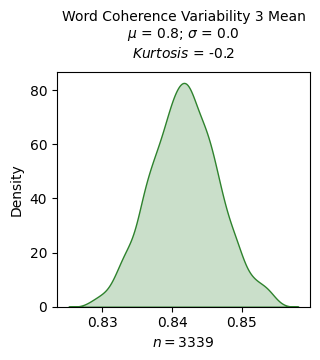

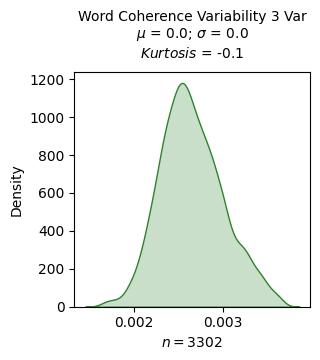

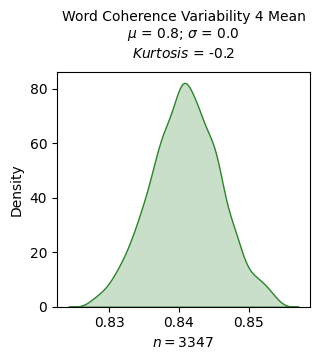

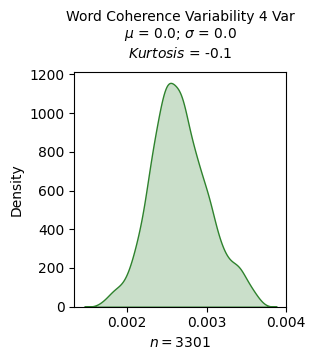

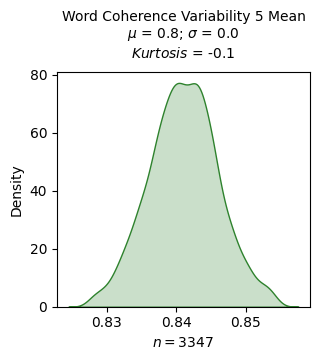

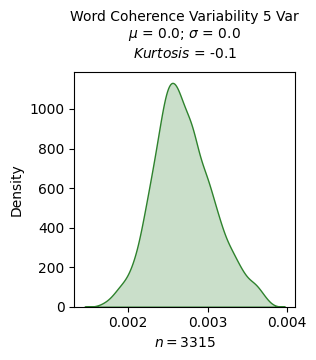

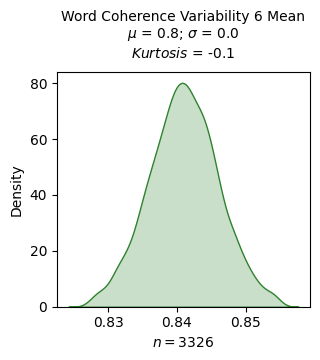

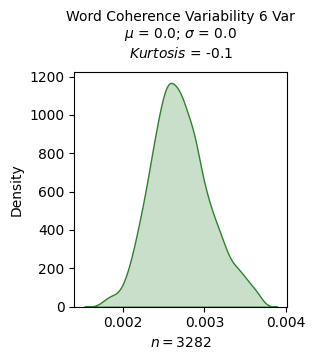

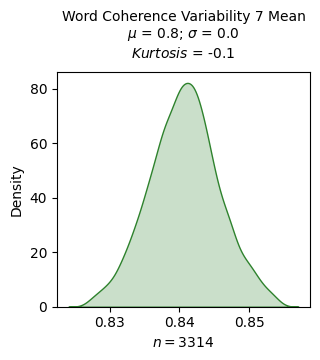

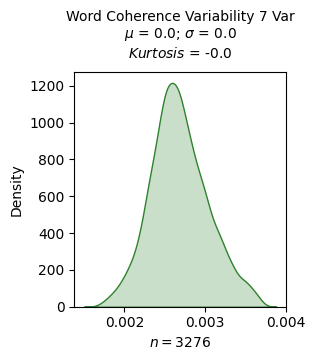

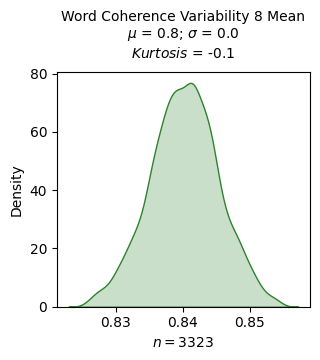

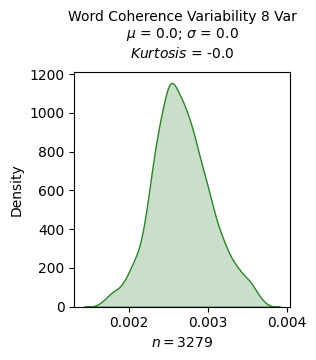

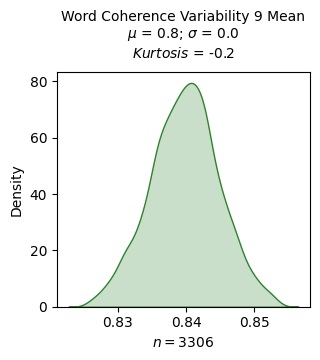

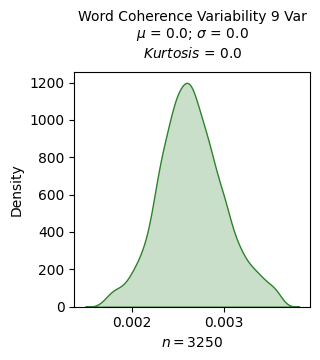

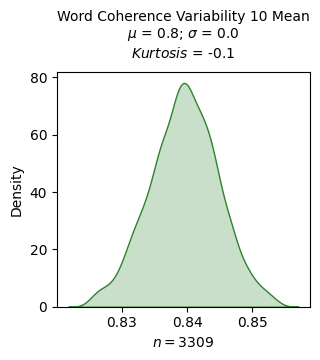

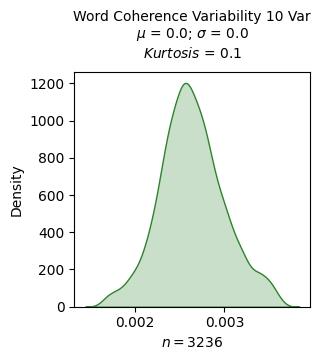

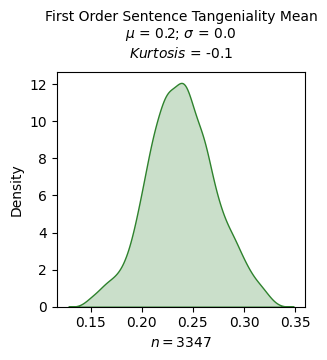

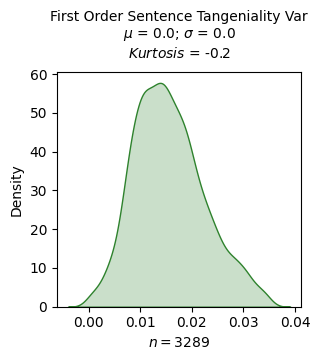

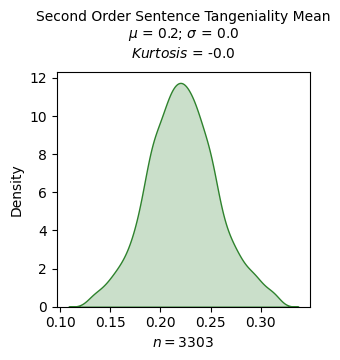

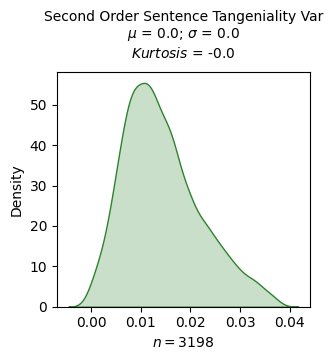

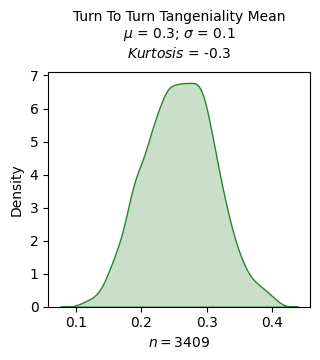

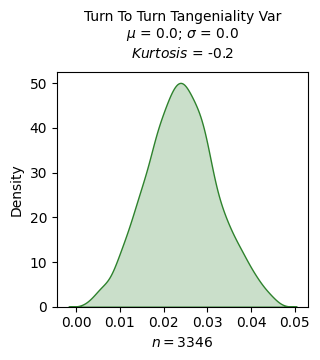

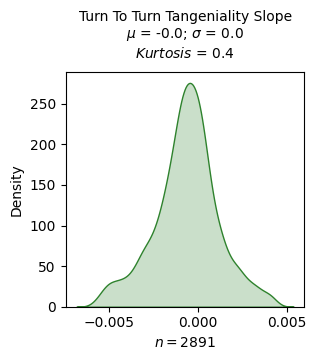

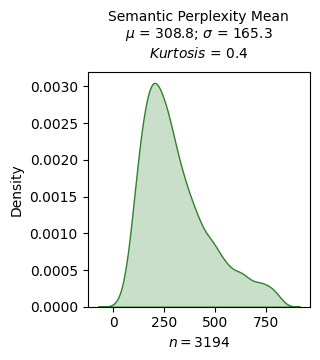

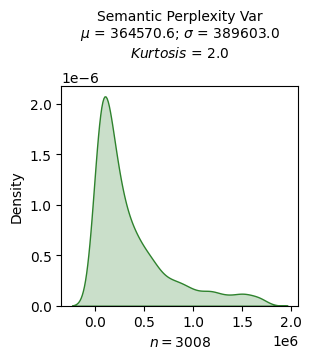

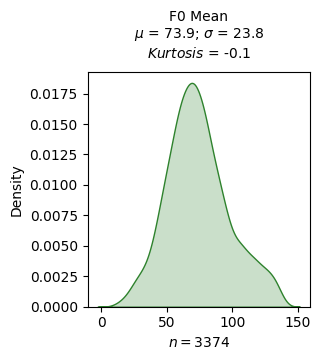

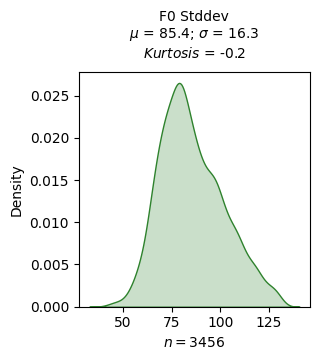

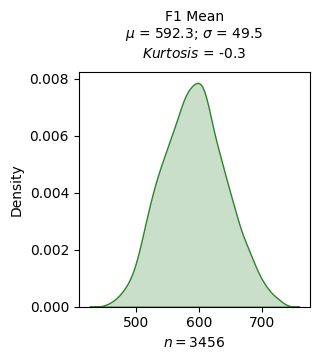

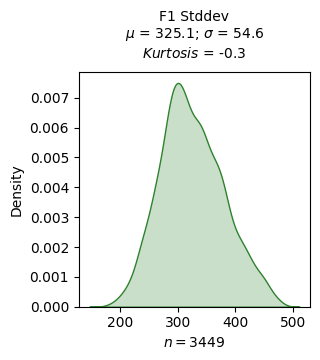

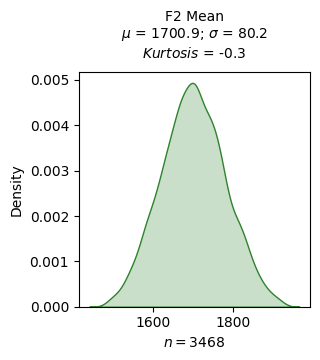

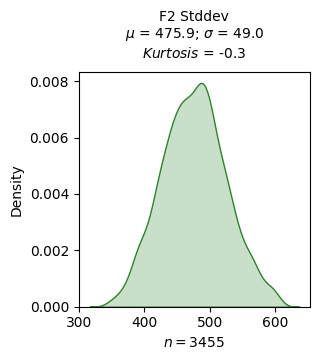

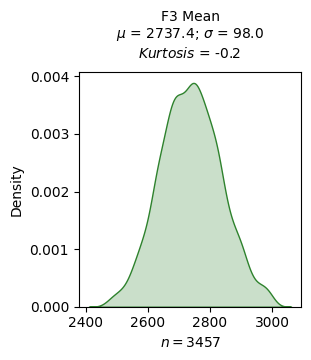

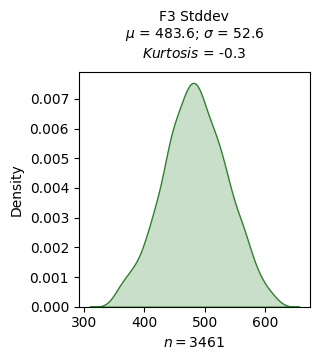

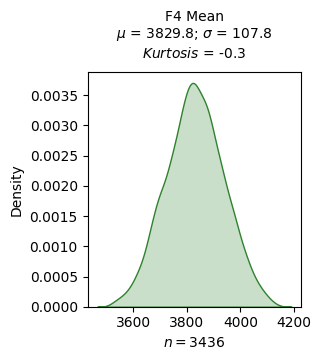

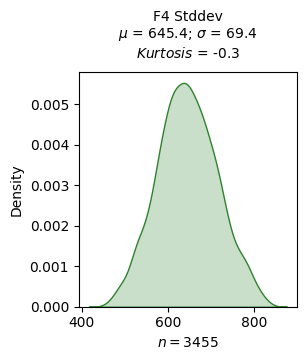

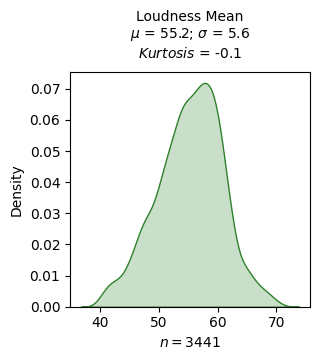

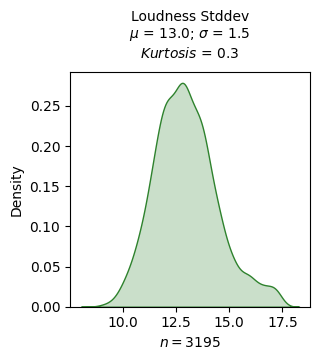

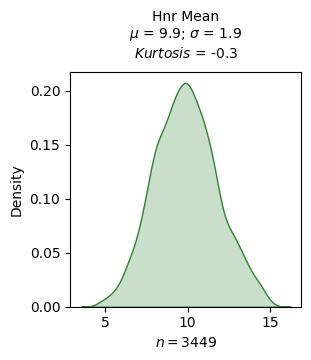

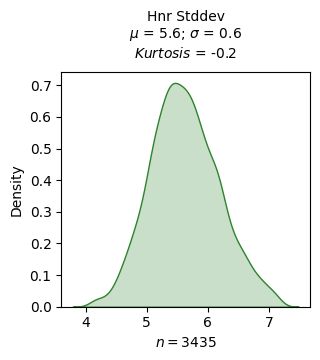

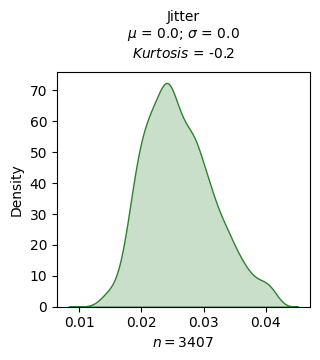

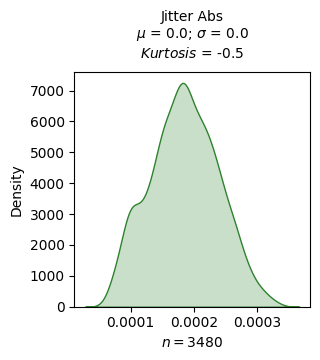

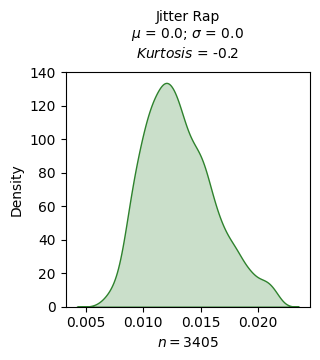

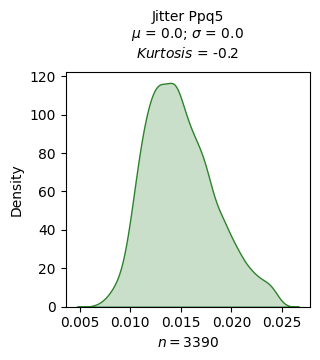

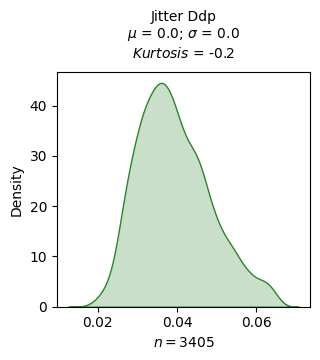

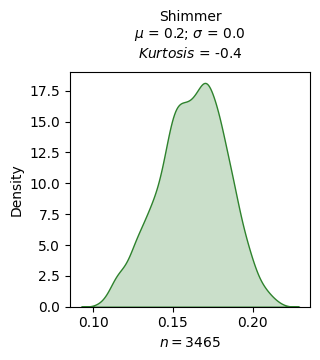

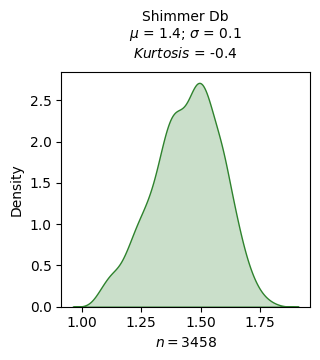

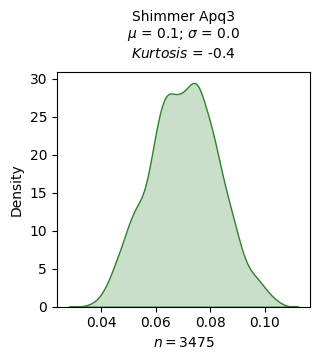

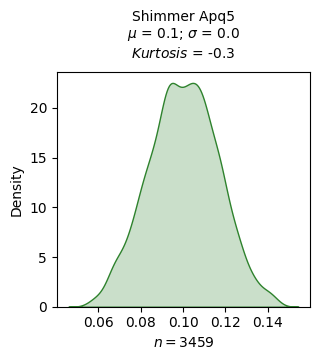

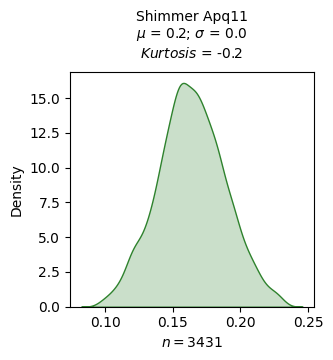

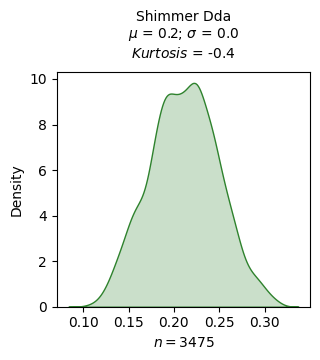

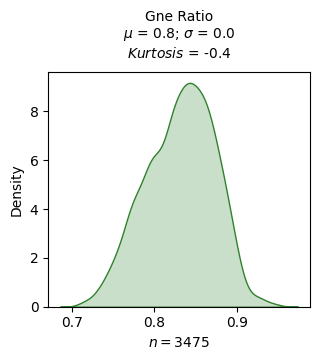

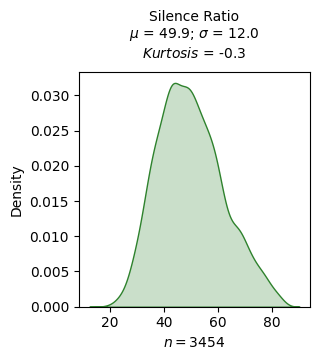

In [25]:
for dhm in dhms:
    distribution(df_clean, dhm, dhm.replace('_', ' ').title(), 'density plot', dpi=100)

In [26]:
for dhm in dhms:
    distribution(df_screening_clean, dhm, dhm.replace('_', ' ').title(), 'density plot', dpi=200, filename=figure_dir+f"3.2_scr_density_{dhm}.png")

In [ ]:
for dhm in dhms:
    distribution(df_bl_clean, dhm, dhm.replace('_', ' ').title(), 'density plot', dpi=200, filename=figure_dir+f"3.2_bl_density_{dhm}.png")

##### 3.2.1 - DHMs vs. Age

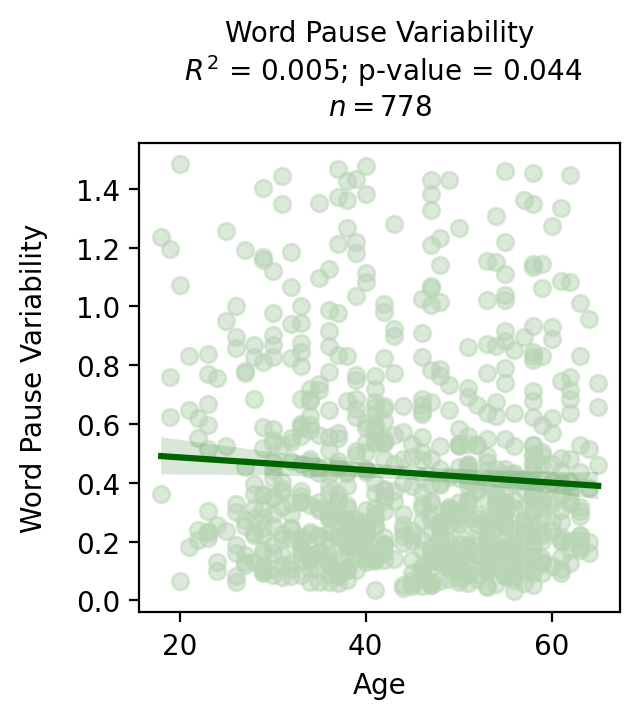

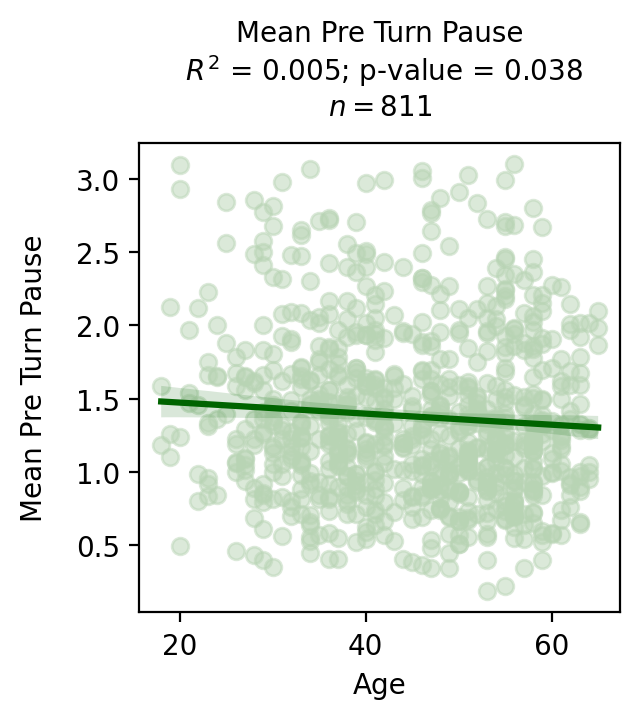

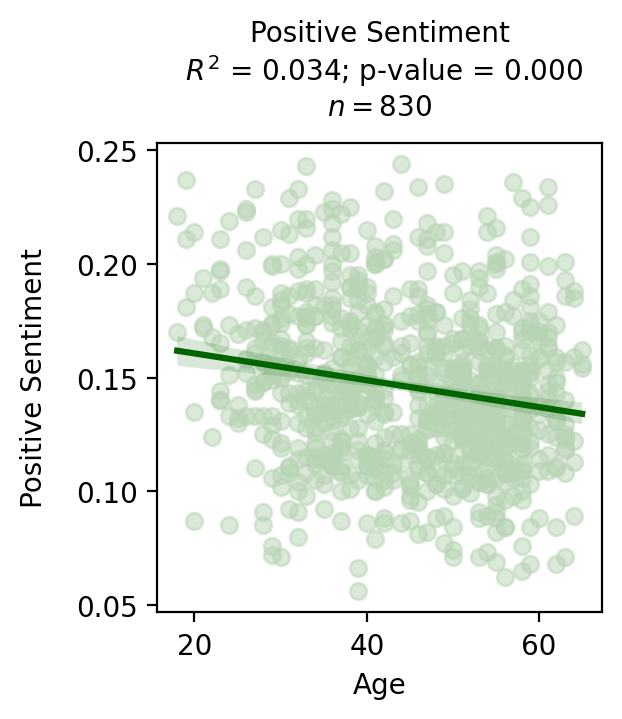

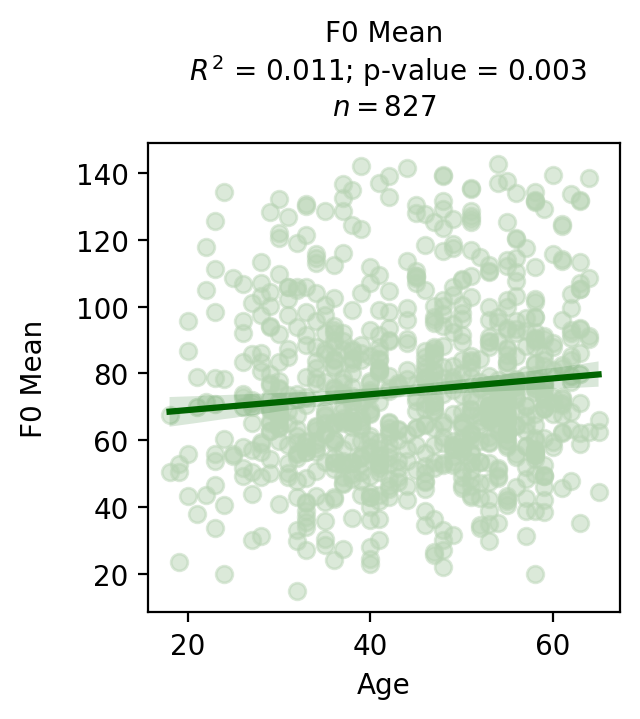

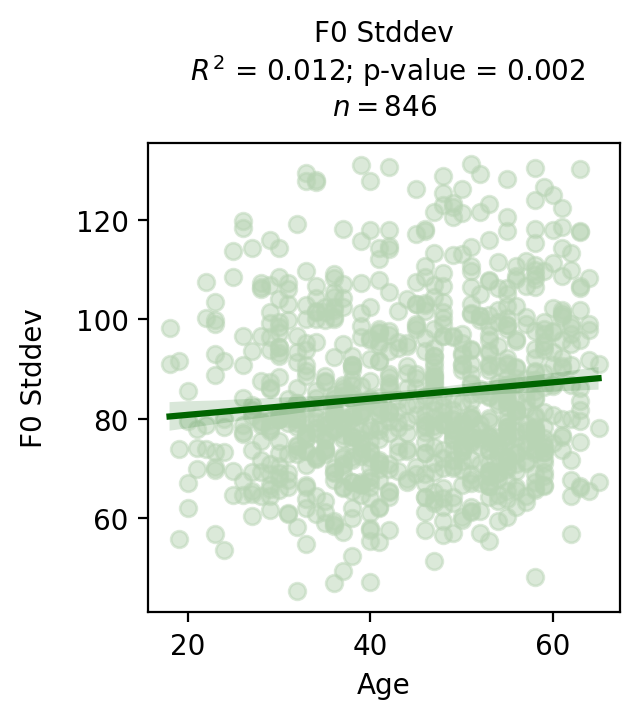

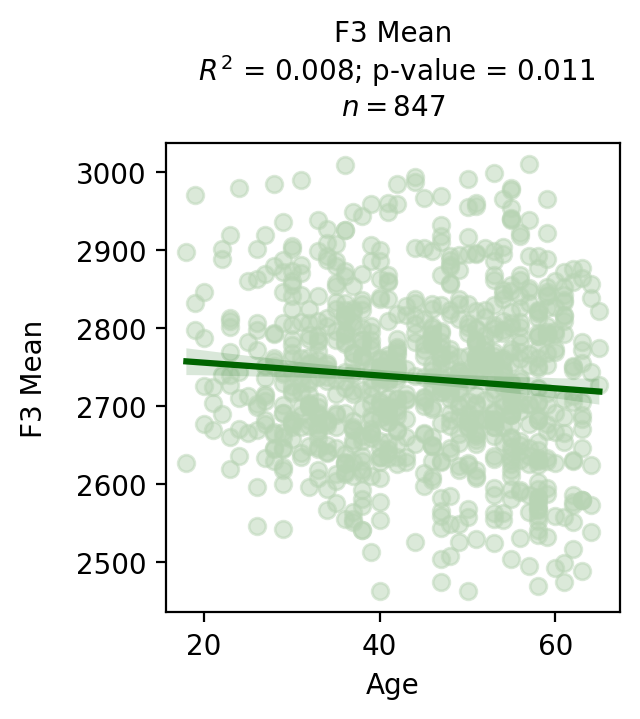

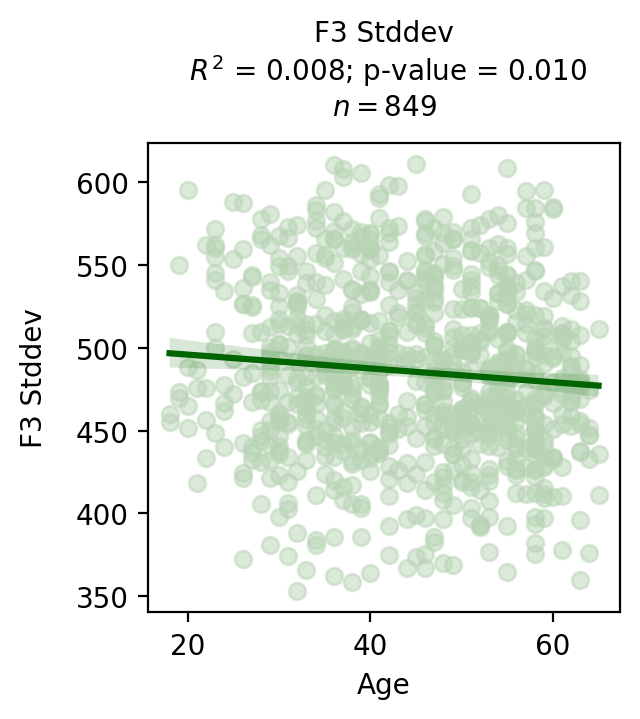

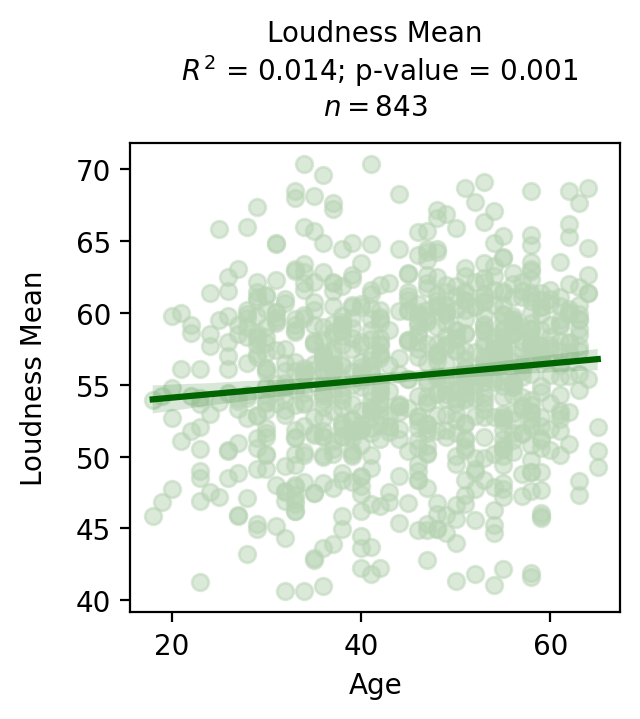

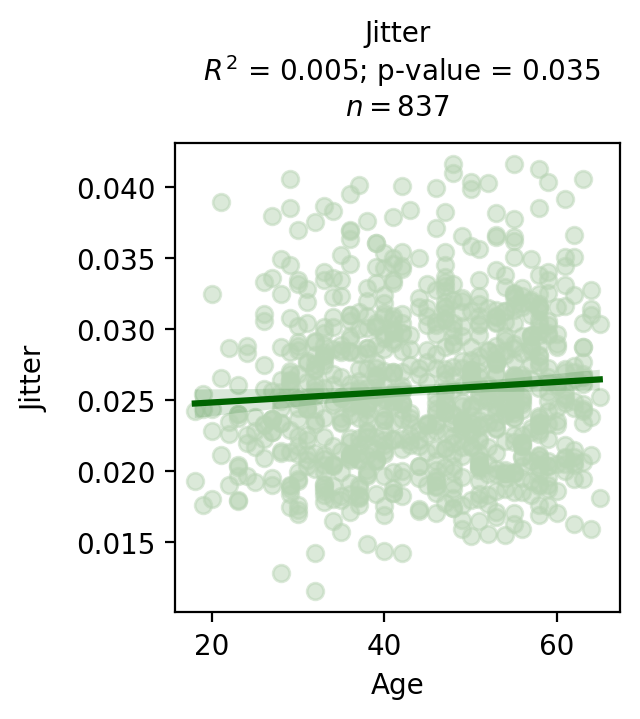

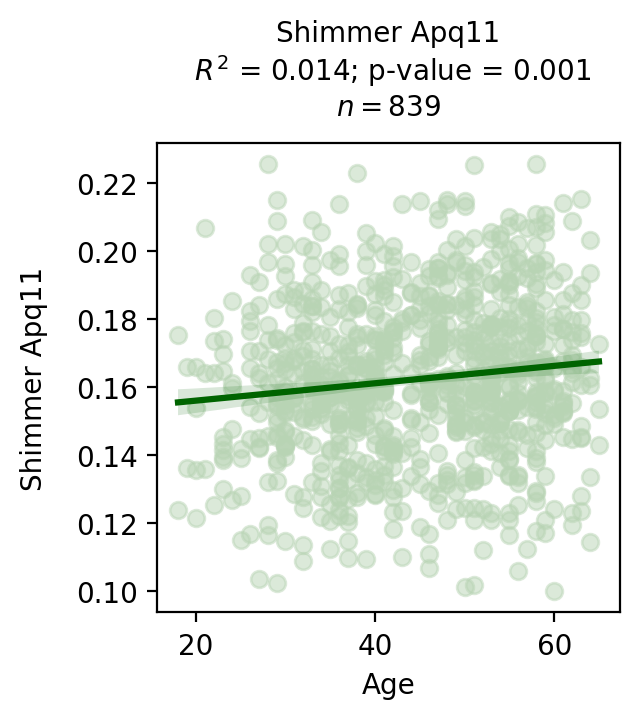

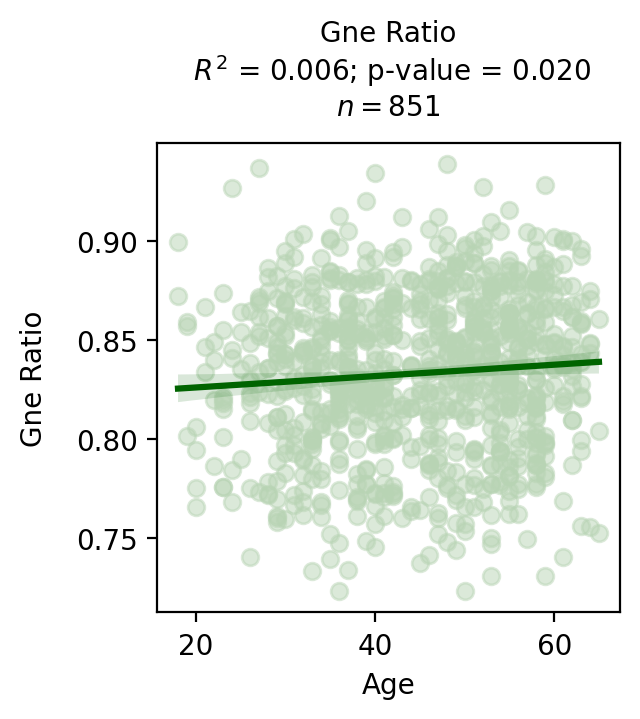

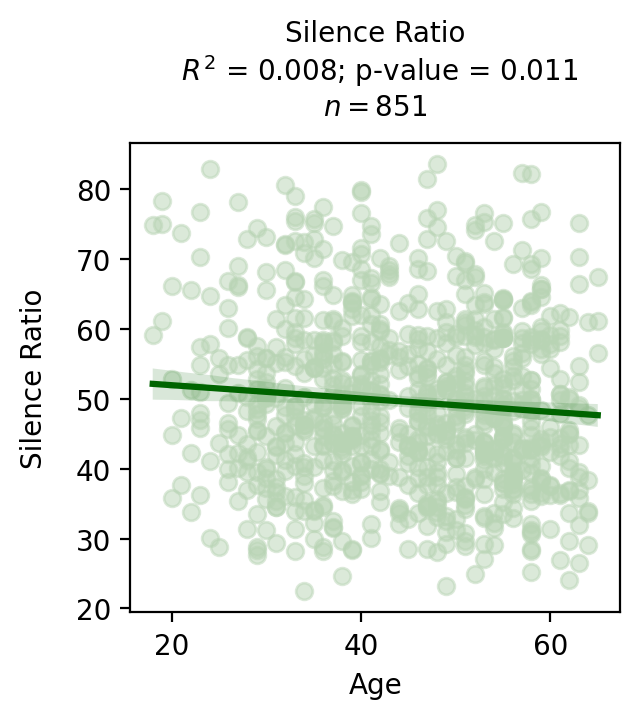

In [27]:
# Scatterplots between DHM and age, with Pearson correlation
for dhm in dhms:
    dhm_name = dhm.replace("_", " ").title()
    scatterplot(df_screening_clean, 'age', [dhm], 'Age', dhm.replace('_', ' ').title(), dhm.replace('_', ' ').title(), 0.05, 'corr', dpi=200)
    scatterplot(df_screening_clean, 'age', [dhm], 'Age', dhm.replace('_', ' ').title(), dhm.replace('_', ' ').title(), 0.05, 'corr', dpi=200, filename=figure_dir+f"3.2.1_scatterplot_age_{dhm}.png")

In [17]:
summaries = []
df2 = df_screening_clean.copy()

for dhm in dhms:
    df_plot = df2.dropna(subset=['age', dhm]).copy()

    dep_var_data = df_plot['age']
    ind_var_data = df_plot[dhm]

    # conduct pearson correlation
    r_value, pval = stats.pearsonr(dep_var_data, ind_var_data)

    if pval < 0.05:
        if r_value > 0:
            str_res = '+'
        else:
            str_res = '-'

        str_res += f', p_value={np.round(pval,3)}'
        str_res += f', r={np.round(r_value, 3)}'
        summaries.append(str_res)
    else:
        summaries.append('')

In [18]:
summary_data = {
    'DHM': [item.replace('_', ' ').title() for item in dhms],
    'Relationship with age': summaries
}

df_summaries = pd.DataFrame(summary_data)
pd.set_option('display.max_rows', None)
df_summaries

,DHM,Relationship with age
0,File Length,
1,Speech Length In Minutes Adjusted,
2,Speech Length In Words Adjusted,
3,Mean Turn Length In Minutes,
4,Mean Turn Length In Words,
5,Speaker Percentage,
6,Words Per Minute,
7,Syllables Per Minute,
8,Word Pause Length Mean,
9,Word Pause Variability,"-, p_value=0.044, r=-0.072"


##### 3.2.2 - DHMs vs. Sex

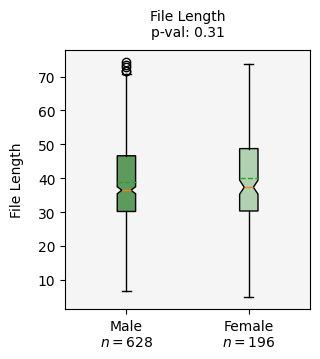

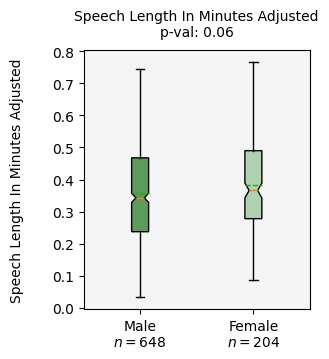

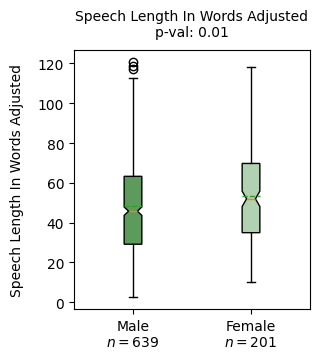

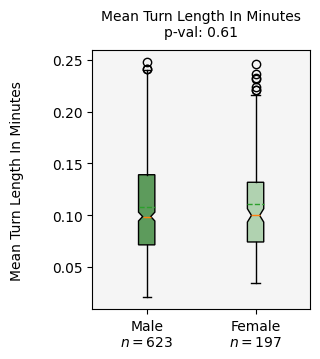

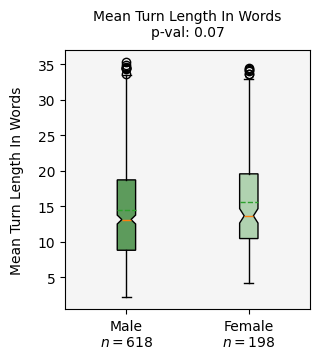

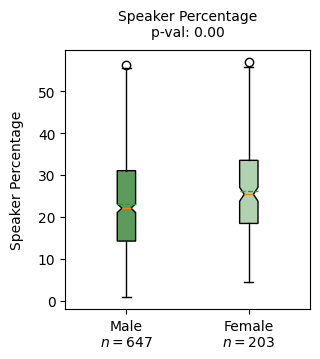

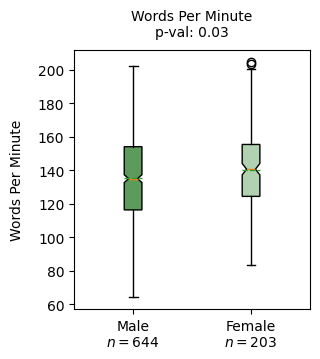

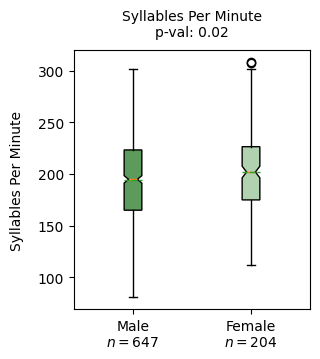

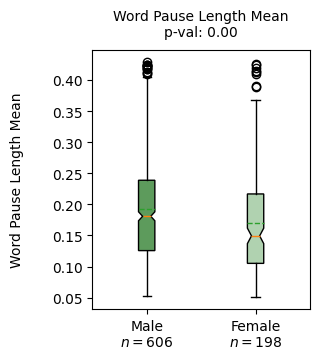

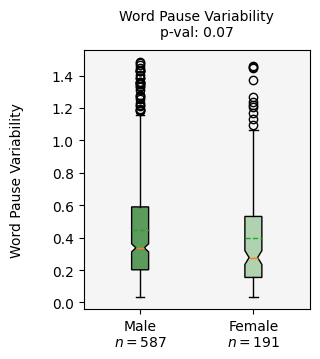

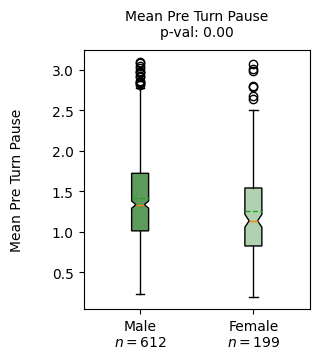

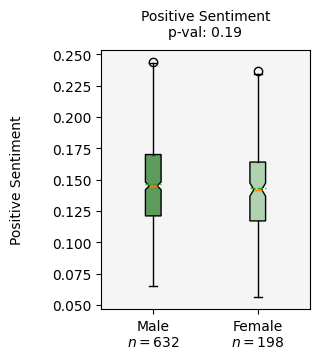

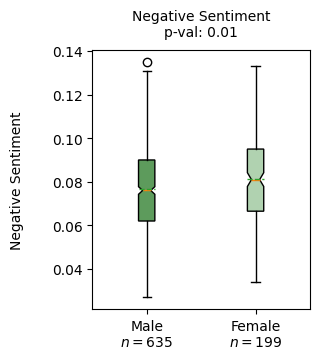

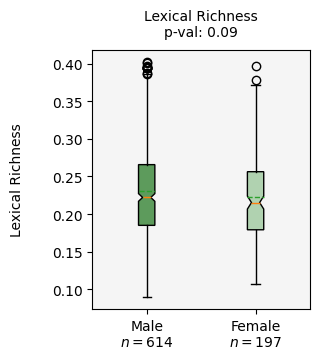

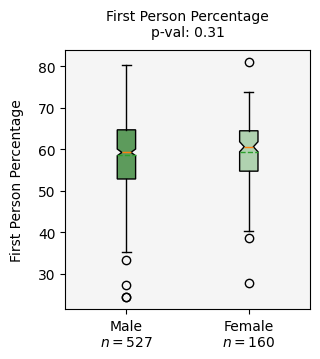

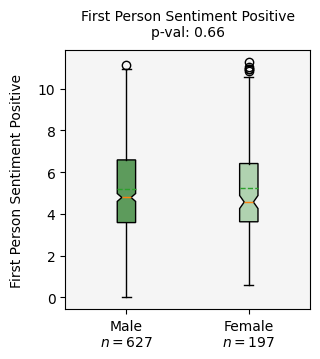

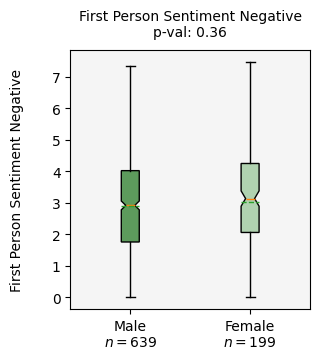

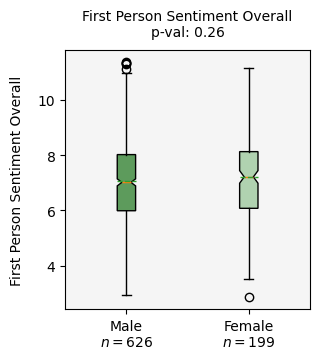

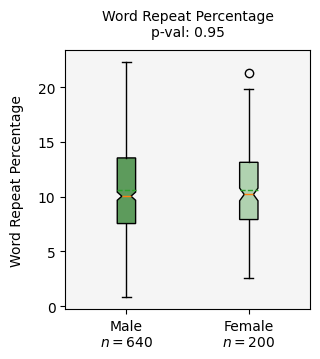

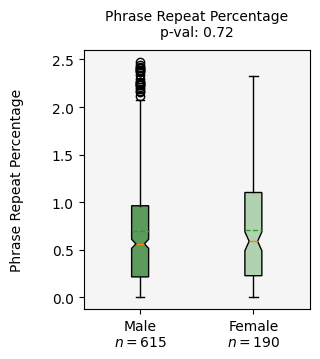

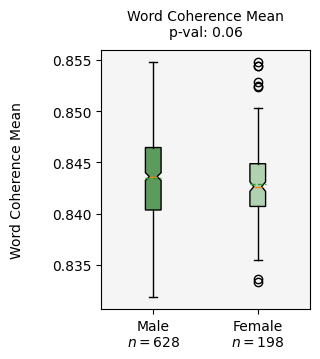

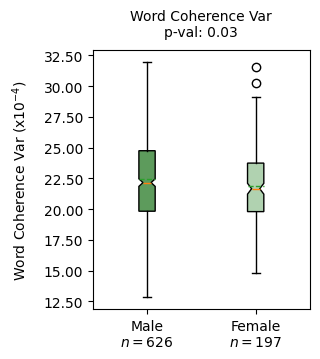

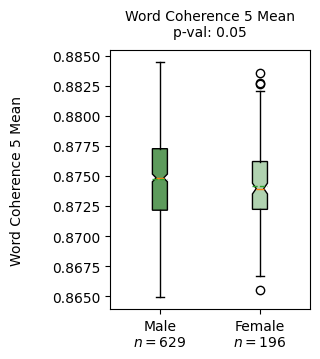

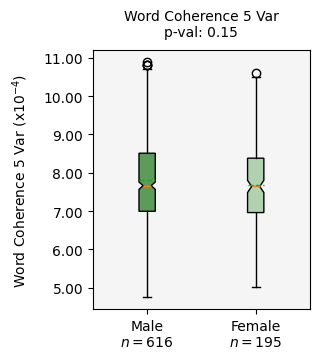

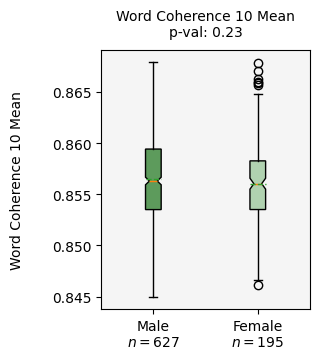

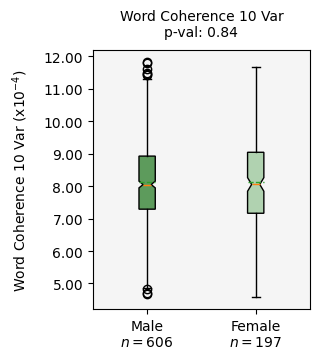

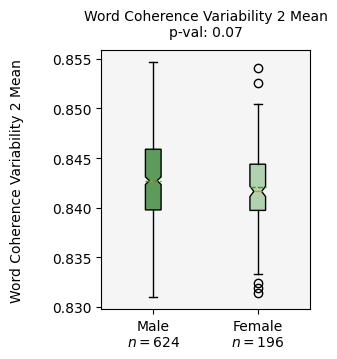

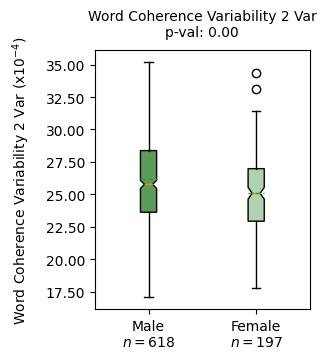

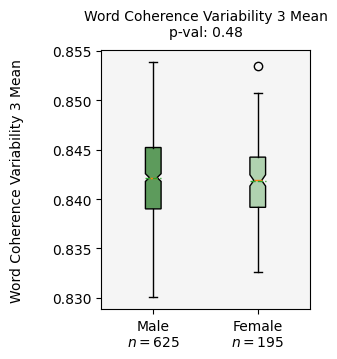

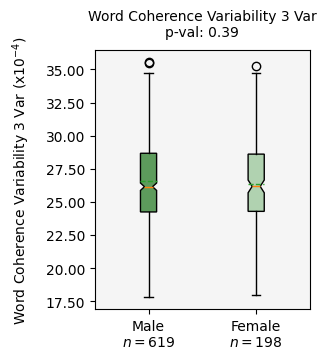

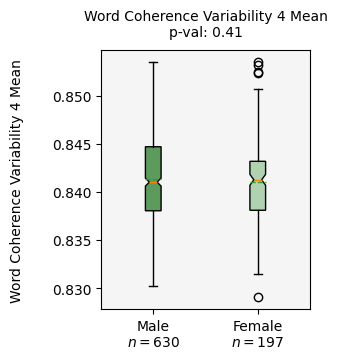

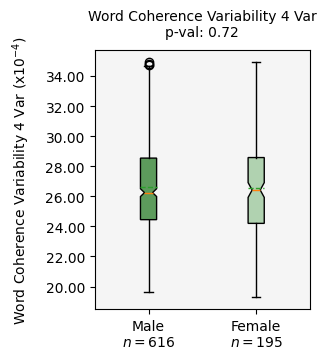

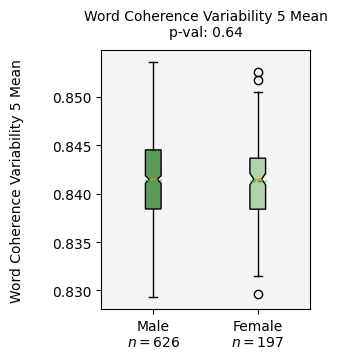

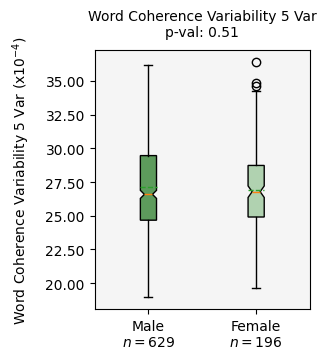

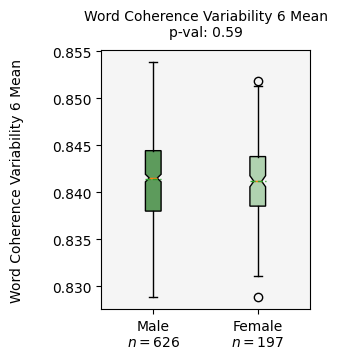

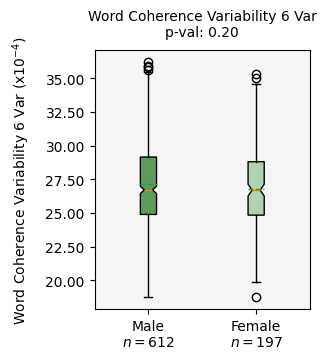

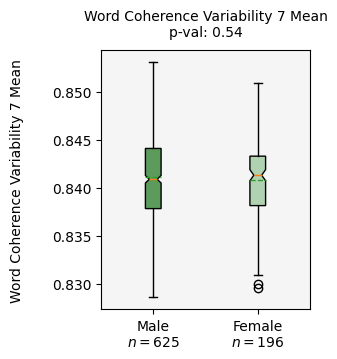

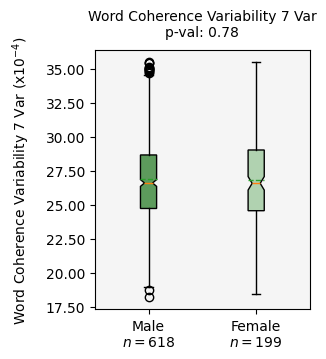

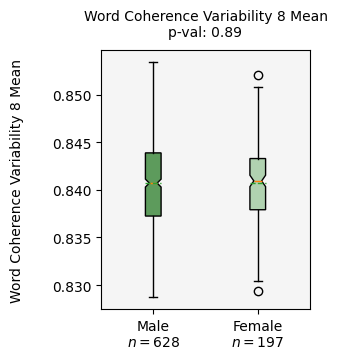

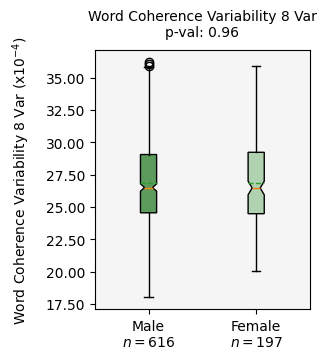

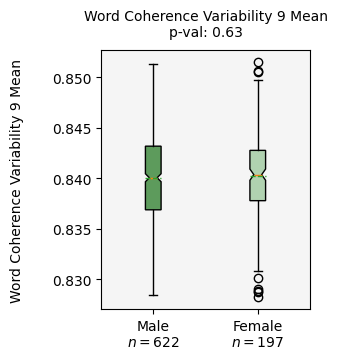

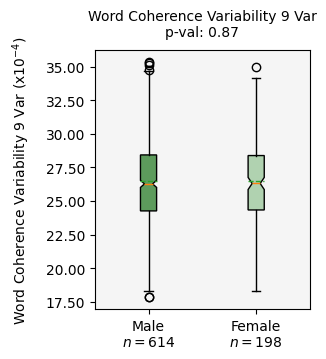

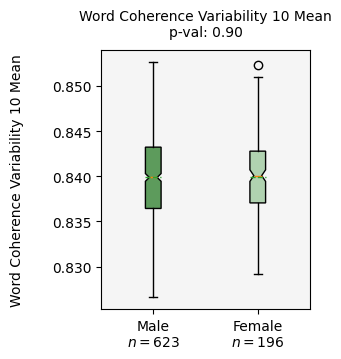

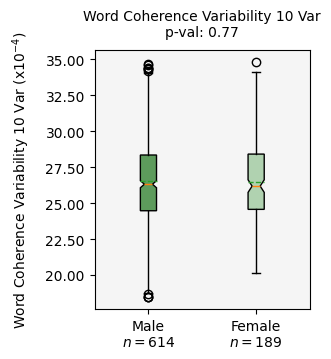

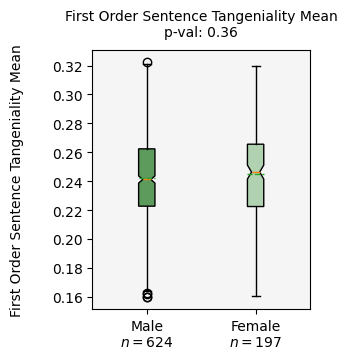

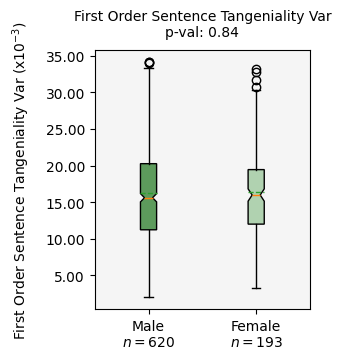

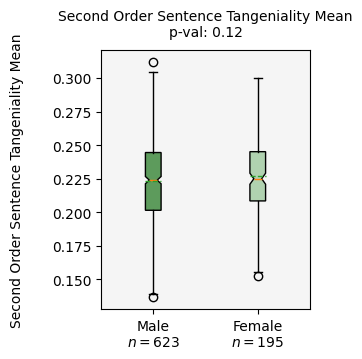

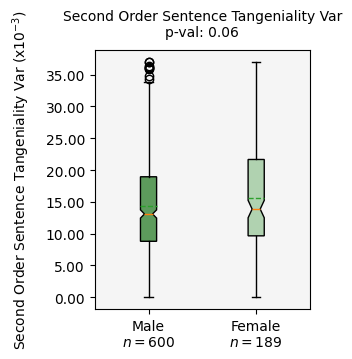

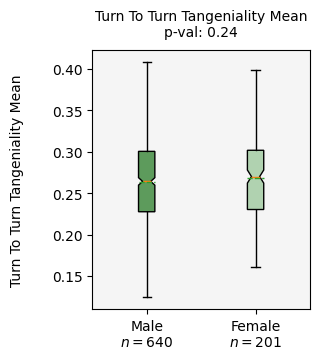

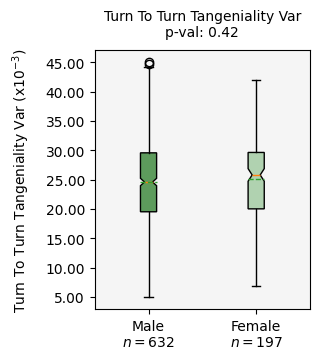

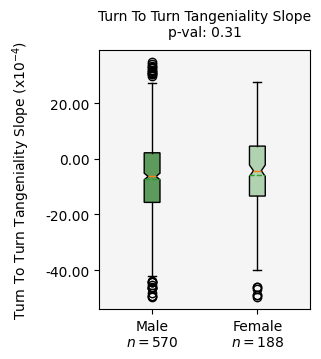

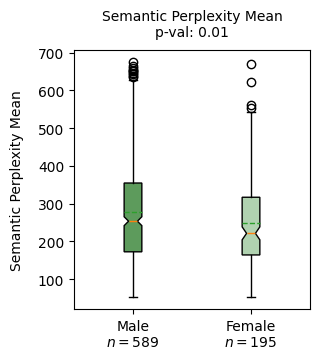

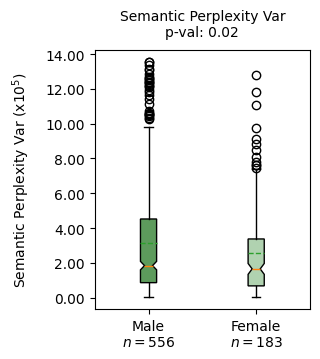

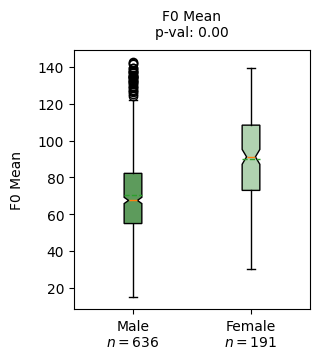

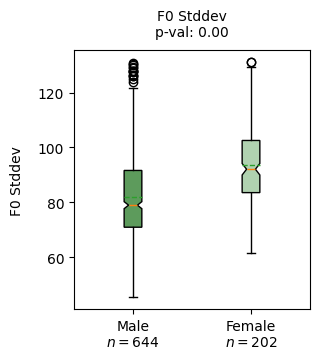

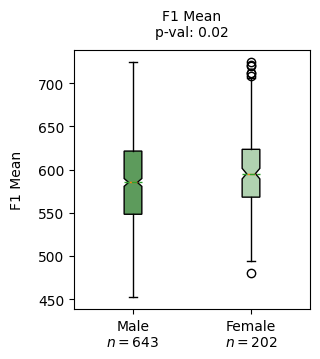

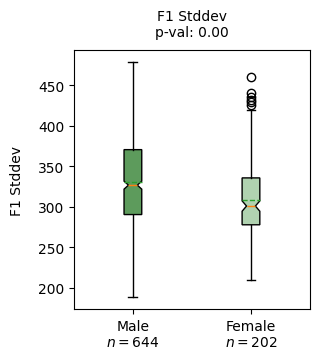

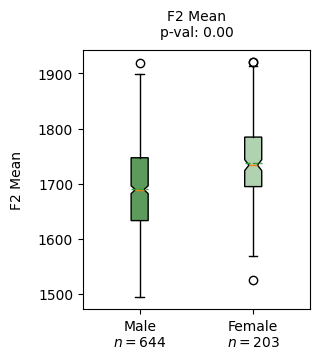

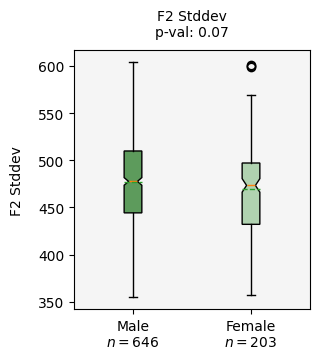

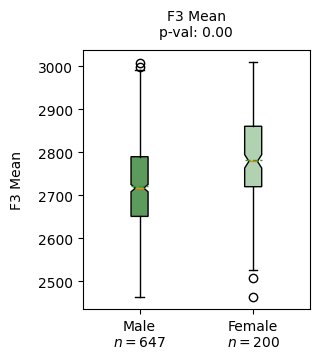

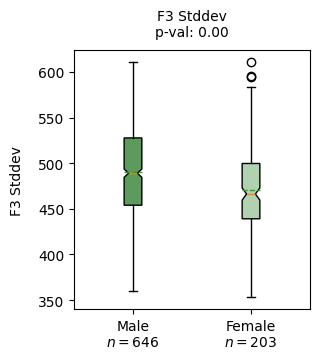

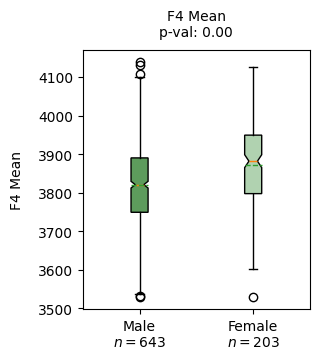

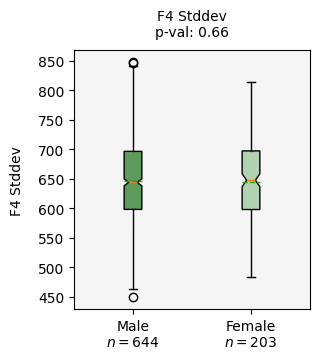

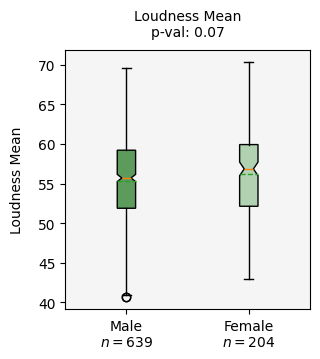

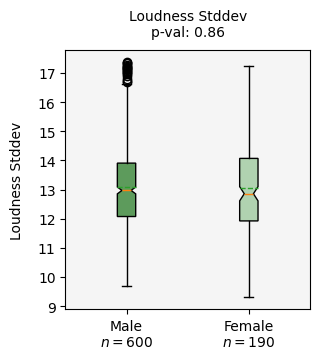

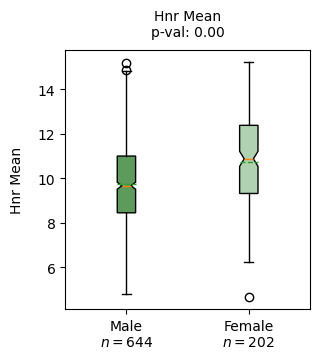

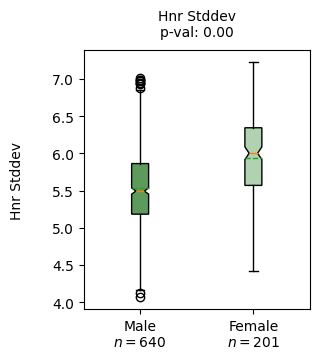

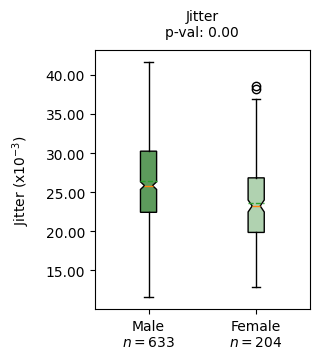

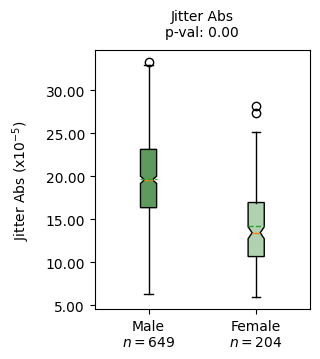

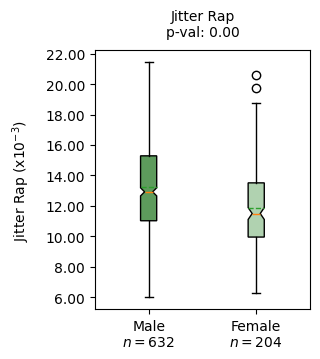

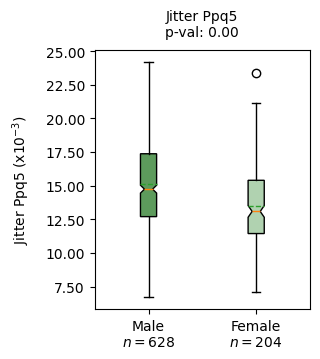

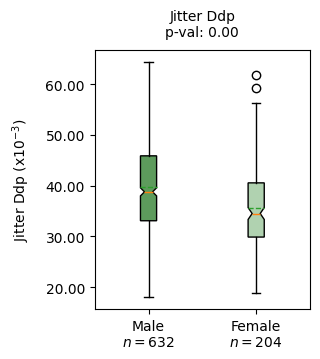

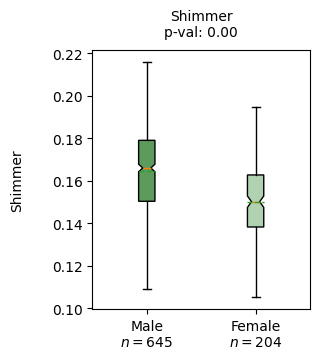

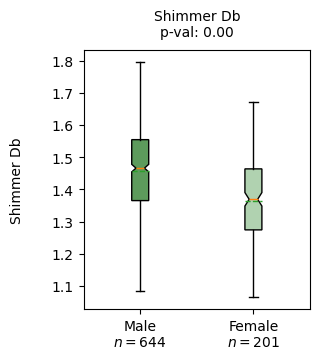

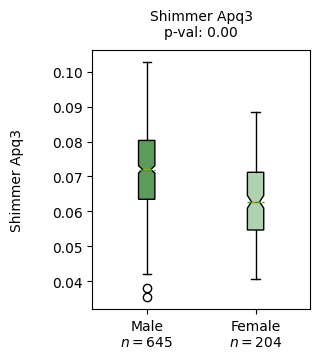

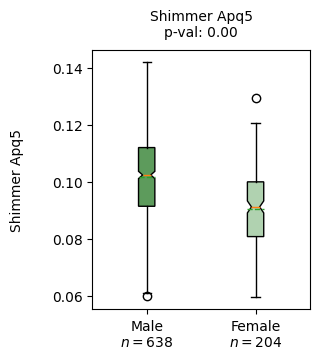

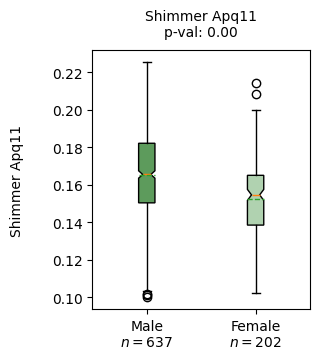

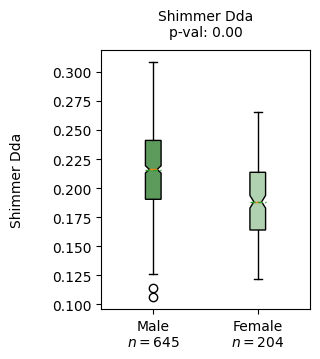

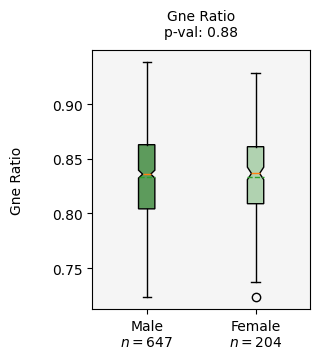

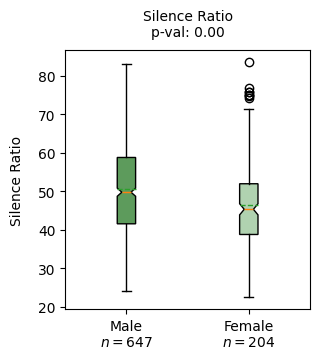

In [32]:
# Boxplots for difference in DHM by sex, with t-test
for dhm in dhms:
    
    # define groups
    male = df_screening_clean[df_screening_clean['male'] == 1][dhm].dropna()
    female = df_screening_clean[df_screening_clean['male'] == 0][dhm].dropna()
    
    # plot boxplot
    boxplot_ttest(dhm.replace('_', ' ').title(), male, female, 'Male', 'Female', 0.05, dpi=200, filename=figure_dir+f"3.3_boxplot_sex_{dhm}.png")
    boxplot_ttest(dhm.replace('_', ' ').title(), male, female, 'Male', 'Female', 1, dpi=100)

In [19]:
summaries = []
df2 = df_screening_clean.copy()

for dhm in dhms:
    
    # define groups
    male = df2[df2['male'] == 1][dhm].dropna()
    female = df2[df2['male'] == 0][dhm].dropna()

    _, pval = stats.ttest_ind(male, female)
    
    if pval < 0.05:
        if np.mean(male) > np.mean(female):
            str_res = 'greater in men'
        else:
            str_res = 'greater in women'

        str_res += f', p_value={np.round(pval,3)}'
        str_res += f', t-test={np.round(_,3)}'
        summaries.append(str_res)
    else:
        summaries.append('')

In [20]:
summary_data = {
    'DHM': [item.replace('_', ' ').title() for item in dhms],
    'Relationship with sex': summaries
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,Relationship with sex
0,File Length,
1,Speech Length In Minutes Adjusted,
2,Speech Length In Words Adjusted,"greater in women, p_value=0.013, t-test=-2.502"
3,Mean Turn Length In Minutes,
4,Mean Turn Length In Words,
5,Speaker Percentage,"greater in women, p_value=0.001, t-test=-3.443"
6,Words Per Minute,"greater in women, p_value=0.026, t-test=-2.231"
7,Syllables Per Minute,"greater in women, p_value=0.017, t-test=-2.398"
8,Word Pause Length Mean,"greater in men, p_value=0.002, t-test=3.047"
9,Word Pause Variability,


##### 3.2.3 - DHMs vs. Race

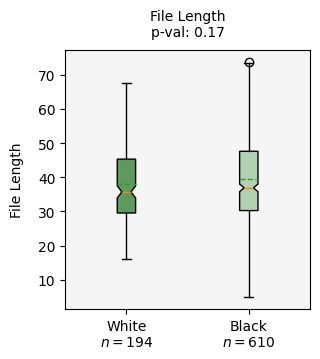

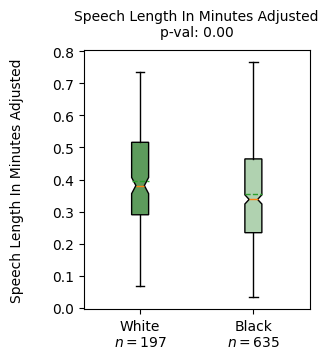

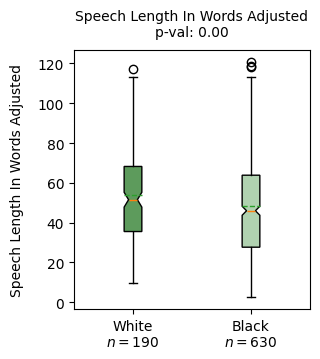

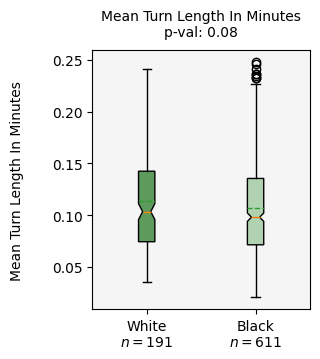

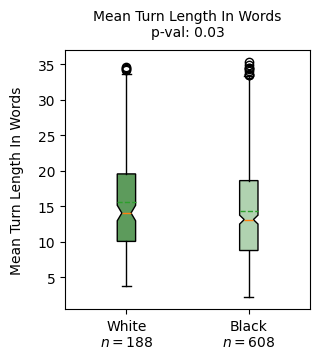

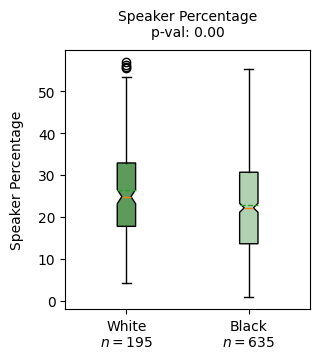

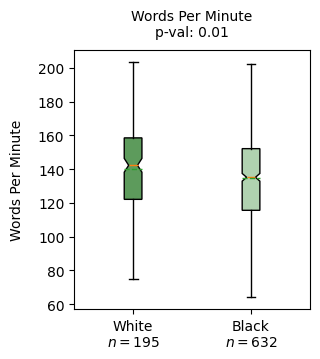

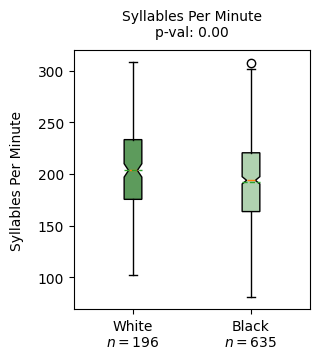

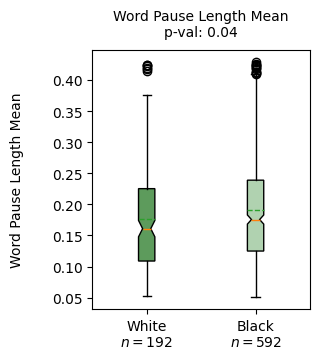

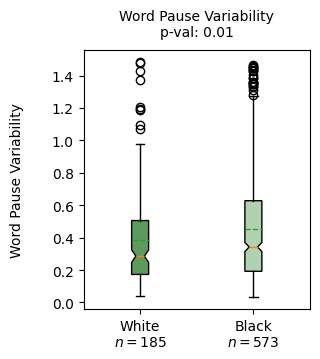

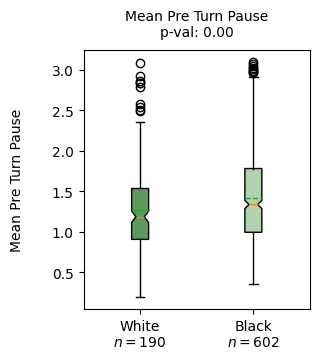

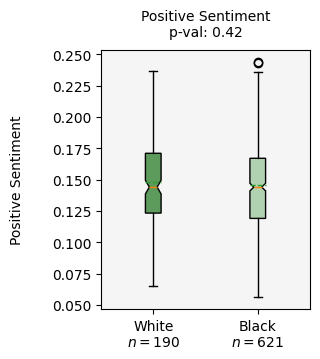

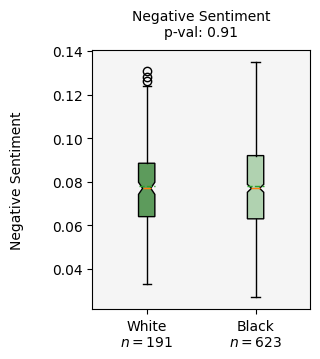

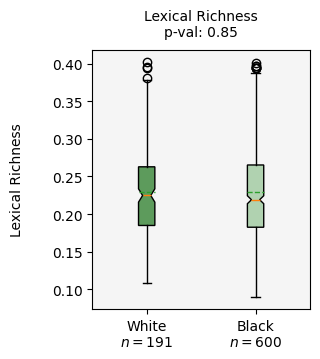

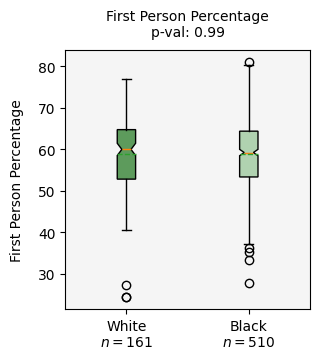

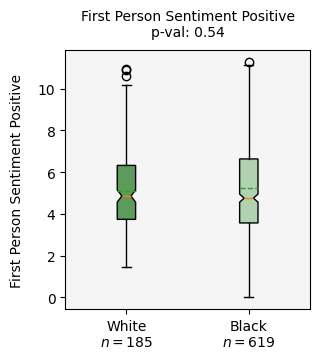

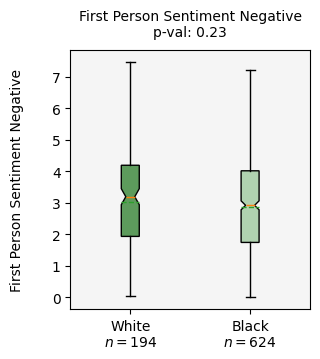

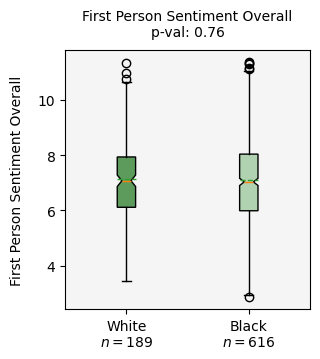

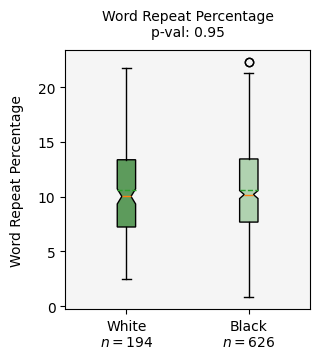

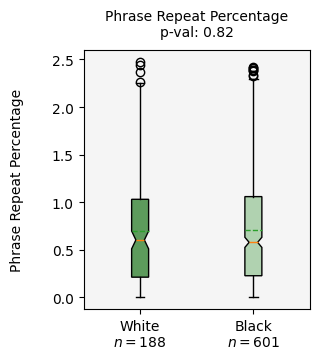

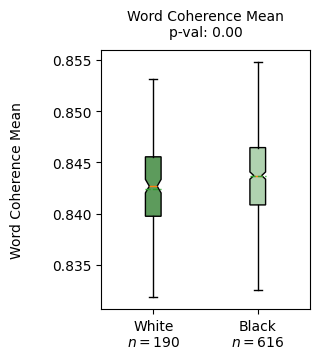

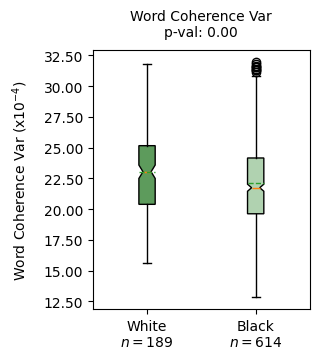

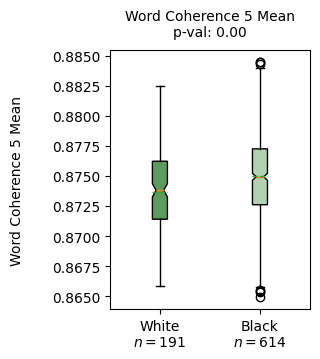

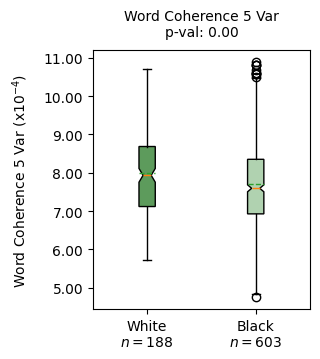

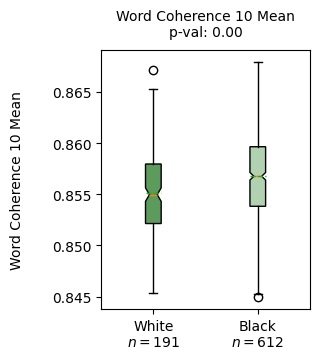

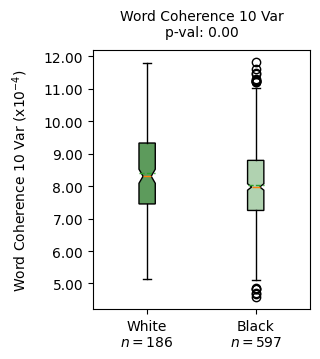

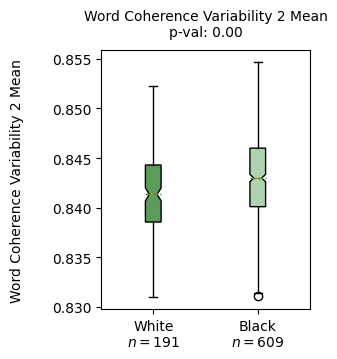

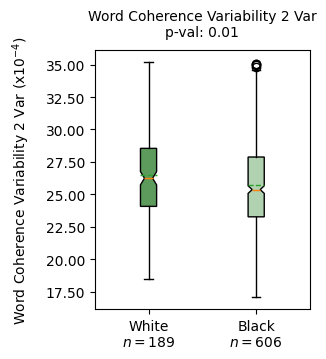

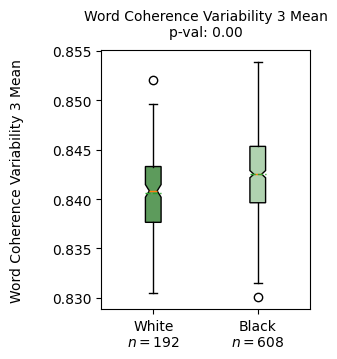

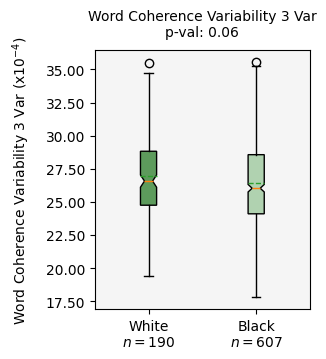

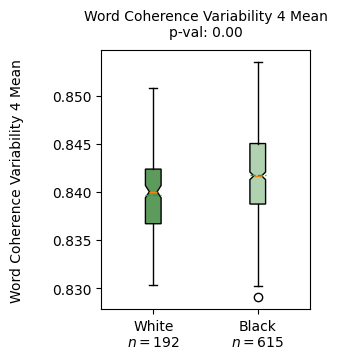

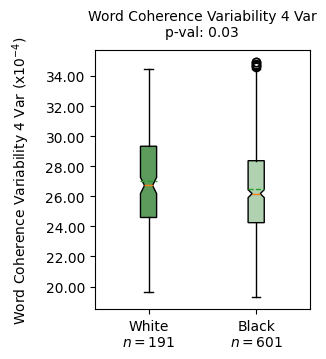

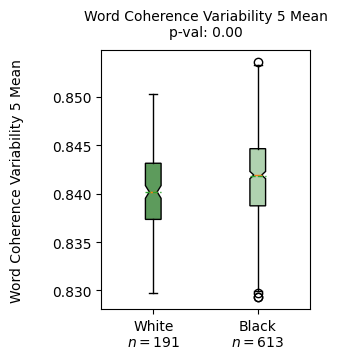

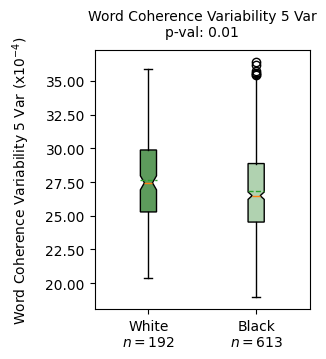

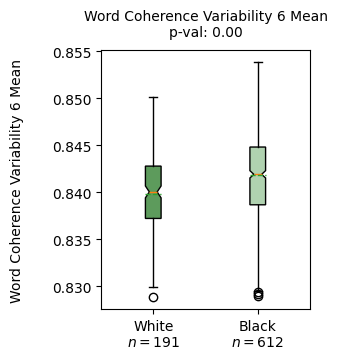

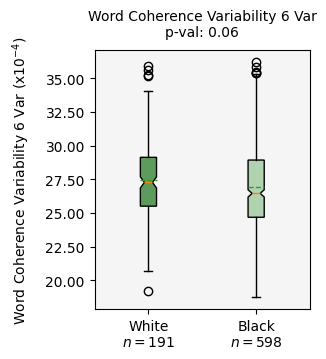

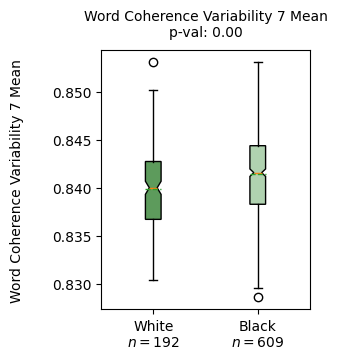

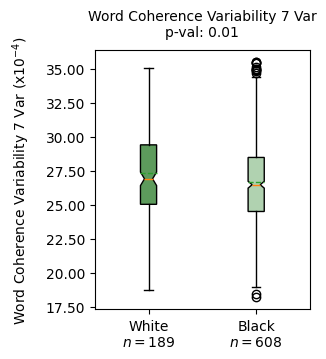

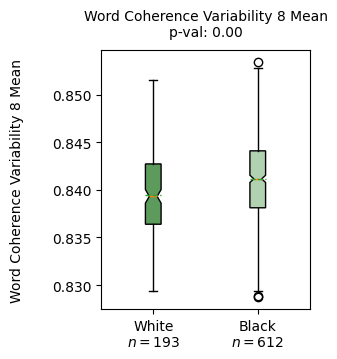

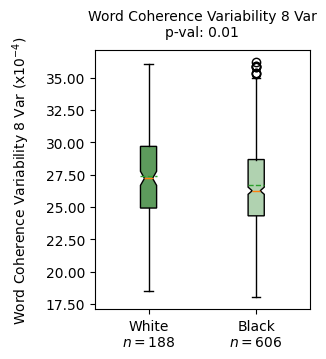

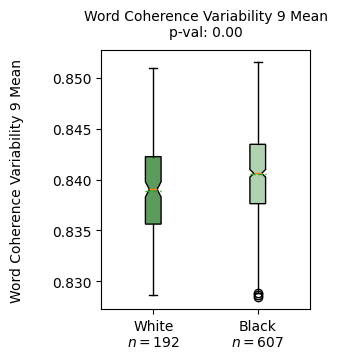

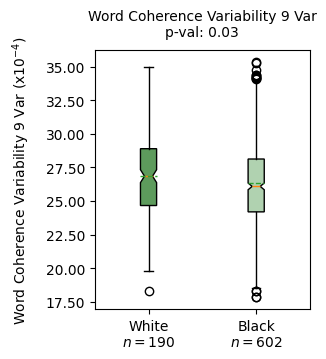

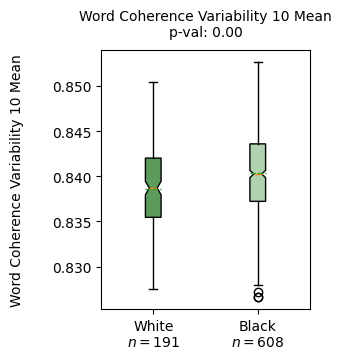

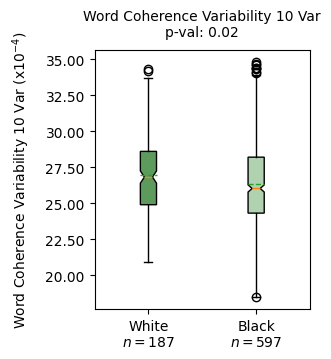

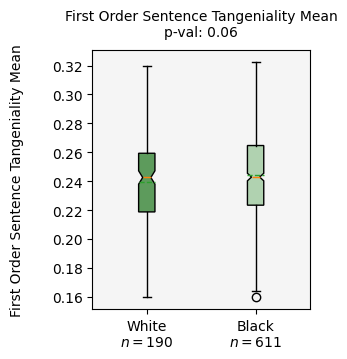

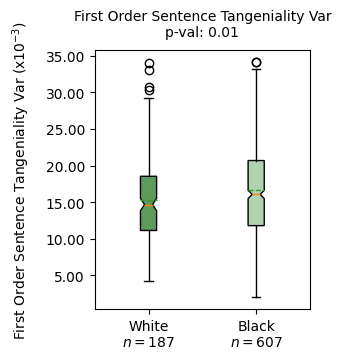

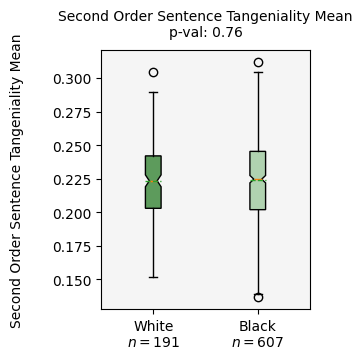

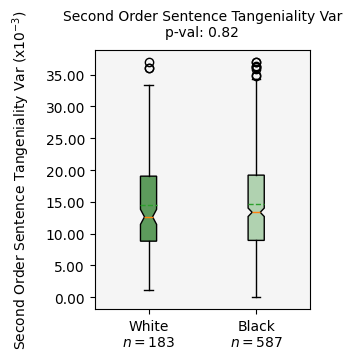

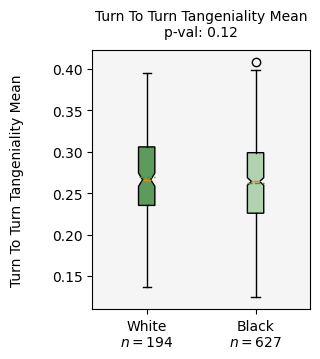

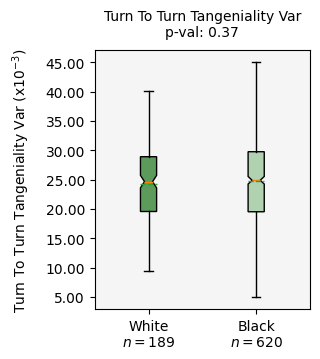

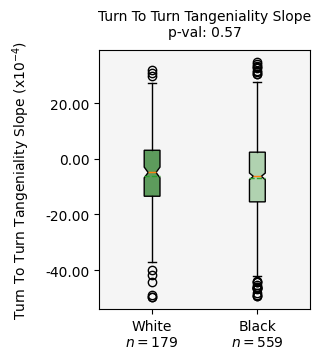

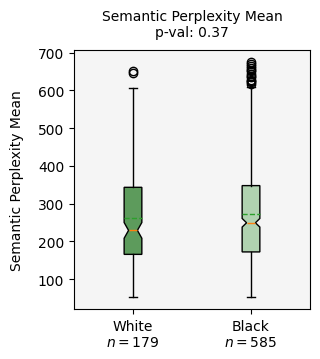

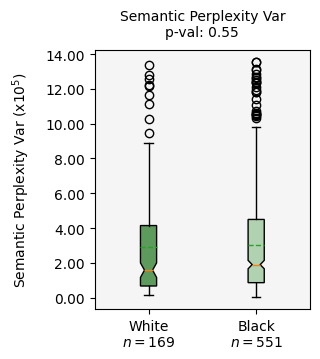

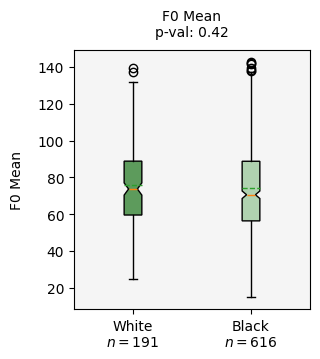

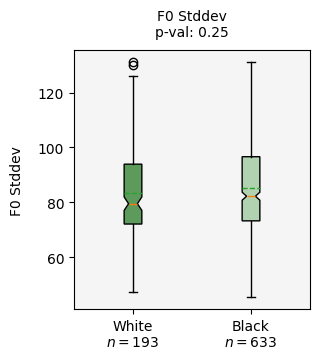

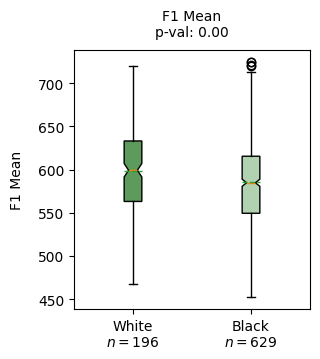

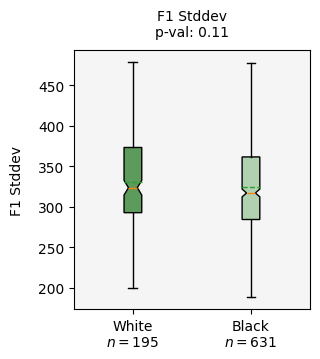

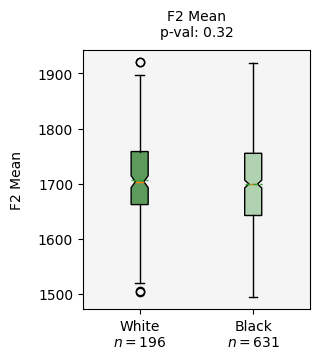

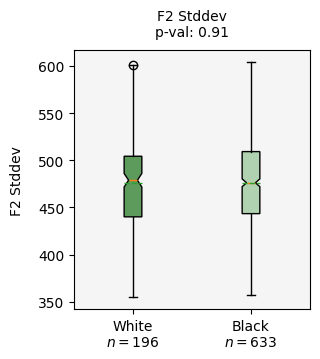

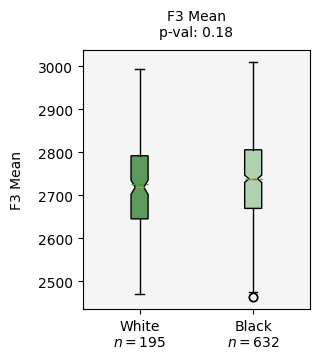

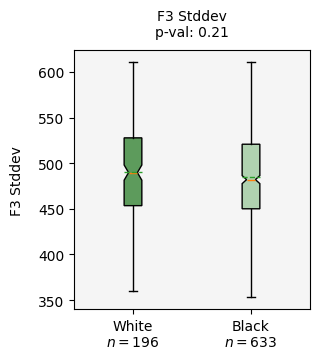

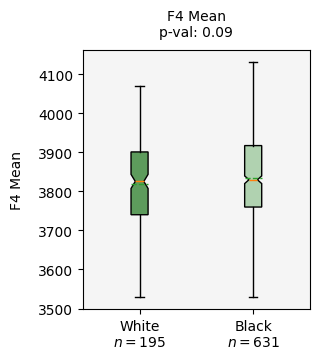

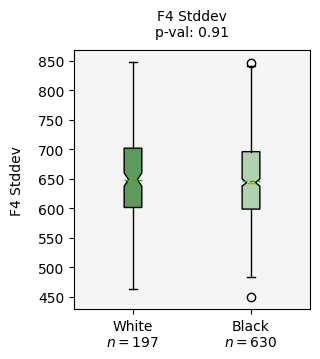

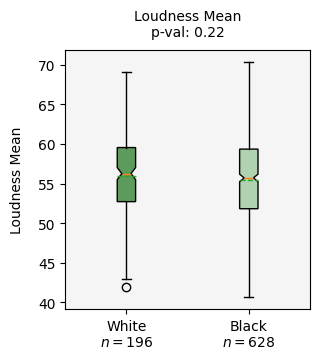

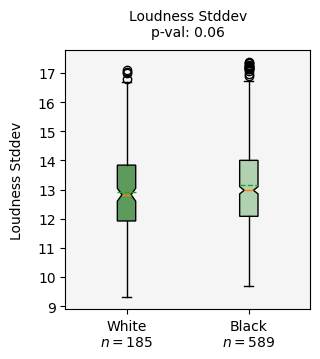

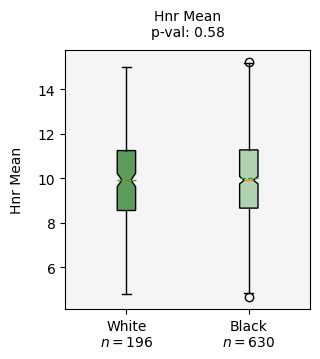

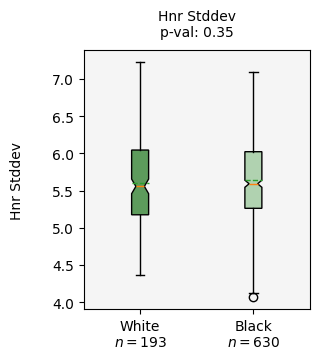

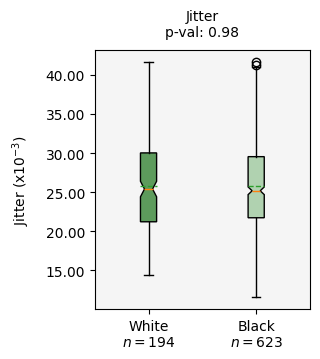

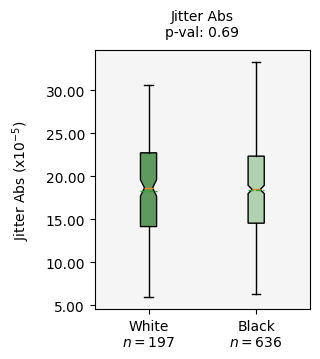

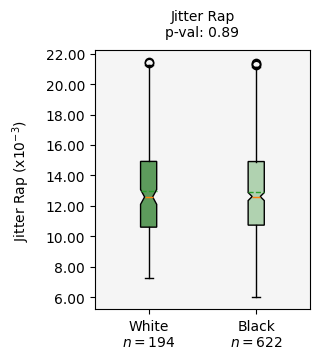

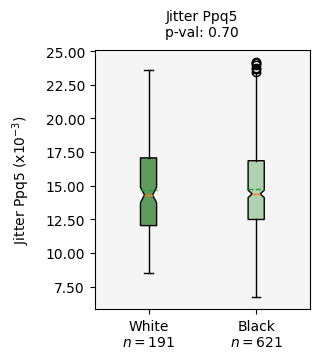

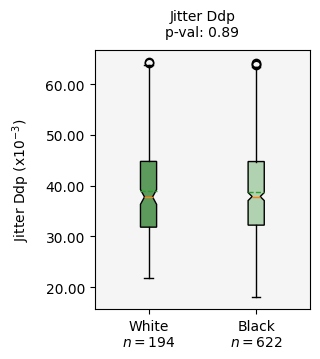

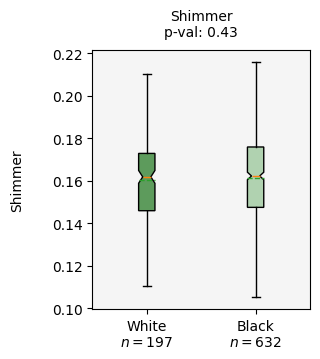

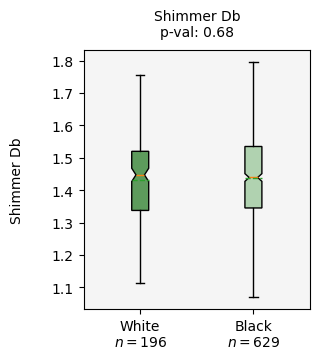

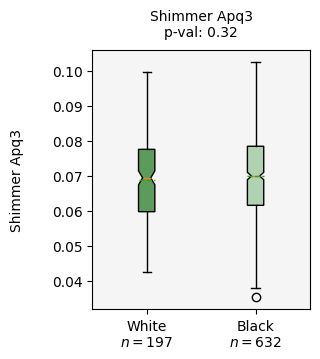

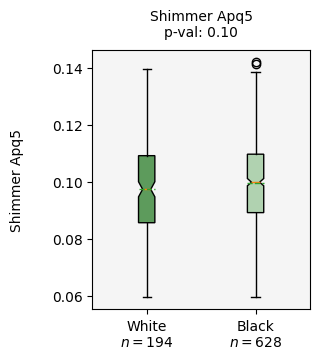

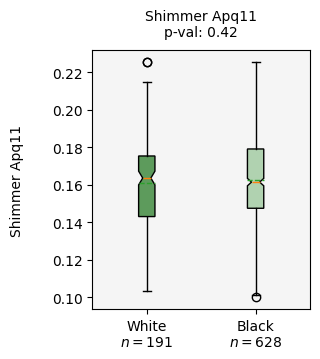

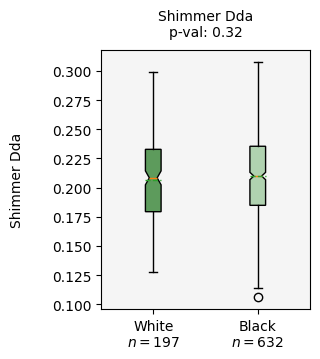

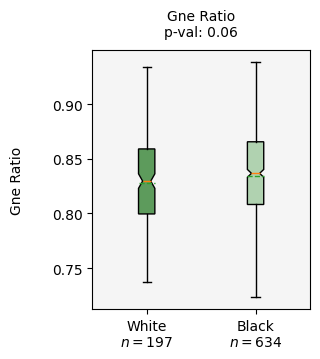

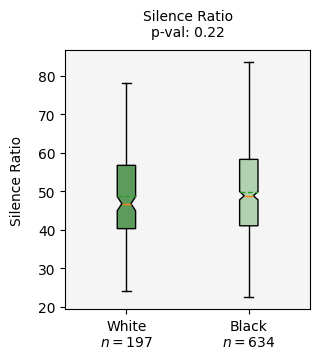

In [35]:
# Boxplots for difference in DHM by race, with ANOVA
for dhm in dhms:
    
    # define groups
    white = df_screening_clean[df_screening_clean['white'] == 1][dhm].dropna()
    black = df_screening_clean[df_screening_clean['black'] == 1][dhm].dropna()
    
    # plot boxplot
    boxplot_ttest(dhm.replace('_', ' ').title(), white, black, 'White', 'Black', 0.05, dpi=200, filename=figure_dir+f"3.3_boxplot_race_{dhm}.png")
    boxplot_ttest(dhm.replace('_', ' ').title(), white, black, 'White', 'Black', 1, dpi=100)

In [17]:
summaries = []
df2 = df_screening_clean.copy()

for dhm in dhms:
    
    # define groups
    white = df2[df2['white'] == 1][dhm].dropna()
    black = df2[df2['black'] == 1][dhm].dropna()

    _, pval = stats.ttest_ind(white, black)
    
    if pval < 0.05:
        if np.mean(white) > np.mean(black):
            str_res = '+ white ppts'
        else:
            str_res = '+ black ppts'

        str_res += f', p_value={np.round(pval,3)}'
        str_res += f', t-test={np.round(_,3)}'
        summaries.append(str_res)
    else:
        summaries.append('')

In [18]:
summary_data = {
    'DHM': [item.replace('_', ' ').title() for item in dhms],
    'Relationship with race': summaries
}

df_summaries = pd.DataFrame(summary_data)
df_summaries

,DHM,Relationship with race
0,File Length,
1,Speech Length In Minutes Adjusted,"+ white ppts, p_value=0.001, t-test=3.249"
2,Speech Length In Words Adjusted,"+ white ppts, p_value=0.004, t-test=2.873"
3,Mean Turn Length In Minutes,
4,Mean Turn Length In Words,"+ white ppts, p_value=0.031, t-test=2.16"
5,Speaker Percentage,"+ white ppts, p_value=0.0, t-test=3.654"
6,Words Per Minute,"+ white ppts, p_value=0.011, t-test=2.547"
7,Syllables Per Minute,"+ white ppts, p_value=0.001, t-test=3.239"
8,Word Pause Length Mean,"+ black ppts, p_value=0.038, t-test=-2.073"
9,Word Pause Variability,"+ black ppts, p_value=0.013, t-test=-2.486"
